# Main-paper role

Results: AI-interaction posterior alpha reversal and Q1 dDTF connectivity differences.

This notebook maps EEG to Wallas-coded behavior, labels AI vs No-AI work, computes posterior alpha time courses, and runs Wallas-based dDTF tests.


# Wallas step mapping onto EEG

In [1]:
import ast, re, warnings
from pathlib import Path
import mne, numpy as np, pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', 200, 'display.width', 250)

PROJECT = Path('/Users/athenasaghi/VSProjects/EEG_CreativityStudy')
CLEAN_DIR = Path('/Users/athenasaghi/Desktop/CleanDATA/clean')
SHEET_CSV, OUT_DIR = PROJECT / 'Data' / 'creativitycodings.csv', PROJECT / 'wallas_analysis'

IGNORE_PIDS = {'P19'}
COND_MAP = {'C': 'control', 'T': 'treatment'}
SESSION_MATCH = {('P12', 'control', 'B1'): 'B2', ('P17', 'control', 'A2'): 'B2', ('P23', 'control', 'B3'): 'B2'}
AHA_CODE, PAIR_WINDOW_SEC, TOLERANCE_SEC = '100', 3.0, 2.0
ILLUMINATION, UNCODED = 'Illumination', 'Uncoded'
PRIORITY = ['Idea generation', 'Implementation', 'Verification', 'Preparation']

## 1. EEG sessions
Cut periods and aha markers on the original recording clock (clean time + preceding cuts).

In [2]:
def load_eeg_session(path):
    raw = mne.io.read_raw_eeglab(str(path), preload=False, verbose=False)
    removed, cuts, aha_raw = 0.0, [], []
    for onset, duration, desc in sorted(zip(raw.annotations.onset, raw.annotations.duration, raw.annotations.description)):
        if desc == 'boundary':
            cuts.append((onset + removed, onset + removed + duration)); removed += duration
        elif desc == AHA_CODE:
            aha_raw.append(onset + removed)
    sfreq = raw.info['sfreq']
    return dict(file=path.name, sfreq=sfreq, n_samples=raw.n_times,
                clean_sec=raw.n_times / sfreq, raw_sec=raw.n_times / sfreq + removed,
                cuts=cuts, aha_raw=np.array(aha_raw))


def raw_to_clean(t, cuts):
    removed = sum(max(0.0, min(t, c1) - c0) for c0, c1 in cuts if t > c0)
    return t - removed


eeg = {}
for path in sorted(CLEAN_DIR.glob('*.set')):
    pid, cond, task = re.match(r'^(P\d+)_(control|treatment)_([AB]\d)_postcleaning\d+\.set$', path.name).groups()
    eeg[(pid, cond, SESSION_MATCH.get((pid, cond, task), task))] = load_eeg_session(path)
print('EEG sessions:', len(eeg), '| subjects:', len({k[0] for k in eeg}))

EEG sessions: 76 | subjects: 19


## 2. Sheet

In [3]:
sheet = pd.read_csv(SHEET_CSV).assign(
    _row=lambda d: d.index,
    _cond=lambda d: d['condition'].map(COND_MAP),
    _t=lambda d: pd.to_timedelta(d['Timestamp']).dt.total_seconds(),
    _aha=lambda d: d['Behavioural Coding'].str.lower().str.contains('aha moment'),
    _steps=lambda d: d['Wallas Step'].map(ast.literal_eval),
)
sheet = sheet[~sheet.Pid.isin(IGNORE_PIDS)]
print('Rows without timestamp (dropped):')
print(sheet.loc[sheet._t.isna(), ['Pid', 'condition', 'name', 'Timestamp', 'Wallas Step']])
sheet = sheet[sheet._t.notna()]
sheet_sessions = {k: g.sort_values(['_t', '_row']).copy() for k, g in sheet.groupby(['Pid', '_cond', 'name'])}
print('Sheet sessions:', len(sheet_sessions))
print('Sheet sessions without EEG:', sorted(set(sheet_sessions) - set(eeg)))
print('EEG sessions without sheet:', sorted(set(eeg) - set(sheet_sessions)))

Rows without timestamp (dropped):
     Pid condition name Timestamp Wallas Step
2100  P4         C   B4       NaN          []
Sheet sessions: 76
Sheet sessions without EEG: []
EEG sessions without sheet: []


## 3. Delay per session
EEG time = sheet time − delay. Delay = median of (sheet aha verbalization − EEG aha marker) over pairs within ±3 s. Sessions without pairs: delay 0.

In [4]:
def aha_pairs(key):
    sheet_aha = sheet_sessions[key].loc[lambda d: d._aha, '_t'].to_numpy()
    out = []
    for t in eeg[key]['aha_raw']:
        if len(sheet_aha):
            s = sheet_aha[np.argmin(np.abs(sheet_aha - t))]
            if abs(s - t) <= PAIR_WINDOW_SEC: out.append(s - t)
    return out, sheet_aha

rows = []
for key in sorted(eeg, key=lambda k: (int(k[0][1:]), k[1], k[2])):
    pairs, sheet_aha = aha_pairs(key); delay = float(np.median(pairs)) if pairs else 0.0
    rows.append(dict(Pid=key[0], condition=key[1], task=key[2], eeg_file=eeg[key]['file'],
                     eeg_aha=len(eeg[key]['aha_raw']), sheet_aha=len(sheet_aha), pairs=len(pairs),
                     pair_diffs_sec=[round(p, 2) for p in pairs], delay_sec=round(delay, 3),
                     max_abs_resid_sec=round(max(abs(p - delay) for p in pairs), 3) if pairs else np.nan))
delays = pd.DataFrame(rows).assign(delay_source=lambda d: np.where(d.pairs > 0, 'aha pairs', 'none (0)'))
print(delays.delay_source.value_counts())
print('Sessions with residual > %.0f s:' % TOLERANCE_SEC)
print(delays.loc[delays.max_abs_resid_sec > TOLERANCE_SEC, ['Pid', 'condition', 'task', 'pair_diffs_sec', 'delay_sec', 'max_abs_resid_sec']])
delays

delay_source
aha pairs    53
none (0)     23
Name: count, dtype: int64
Sessions with residual > 2 s:
    Pid condition task        pair_diffs_sec  delay_sec  max_abs_resid_sec
44  P15   control   A2  [-1.66, -0.66, 1.42]     -0.660              2.083
57  P18   control   B2         [-2.39, 1.92]     -0.233              2.157
61  P20   control   B1   [0.34, -0.32, 2.51]      0.343              2.170
68  P22   control   A1  [2.51, -2.16, -2.16]     -2.157              4.667


,Pid,condition,task,eeg_file,eeg_aha,sheet_aha,pairs,pair_diffs_sec,delay_sec,max_abs_resid_sec,delay_source
0,P3,control,A3,P3_control_A3_postcleaning4.set,0,1,0,[],0.000,NaN,none (0)
1,P3,control,B4,P3_control_B4_postcleaning4.set,0,2,0,[],0.000,NaN,none (0)
2,P3,treatment,A4,P3_treatment_A4_postcleaning1.set,0,0,0,[],0.000,NaN,none (0)
3,P3,treatment,B3,P3_treatment_B3_postcleaning4.set,0,0,0,[],0.000,NaN,none (0)
4,P4,control,A1,P4_control_A1_postcleaning4.set,6,6,5,"[0.42, -0.66, -0.74, -0.74, -1.66]",-0.743,1.167,aha pairs
5,P4,control,B4,P4_control_B4_postcleaning4.set,7,6,3,"[-0.82, -1.49, -1.16]",-1.157,0.333,aha pairs
6,P4,treatment,A4,P4_treatment_A4_postcleaning4.set,5,5,2,"[-1.25, -0.83]",-1.042,0.208,aha pairs
7,P4,treatment,B3,P4_treatment_B3_postcleaning4.set,8,8,4,"[-0.58, -0.24, -2.99, -1.41]",-0.993,2.000,aha pairs
8,P5,control,A2,P5_control_A2_postcleaning4.set,4,4,3,"[-1.16, -0.16, 0.42]",-0.163,0.993,aha pairs
9,P5,control,B3,P5_control_B3_postcleaning4.set,3,3,2,"[-2.66, 0.01]",-1.327,1.333,aha pairs


## 4. Wallas step per row
- Illumination is dropped; a row with only Illumination takes the last available step.
- Multi-step rows keep the highest-priority step: Idea generation > Implementation > Verification > Preparation.
- Empty rows stay Uncoded.

In [5]:
def resolve_steps(g):
    resolved, last = [], None
    for steps in g['_steps']:
        kept = [s for s in steps if s != ILLUMINATION]
        step = min(kept, key=PRIORITY.index) if kept else last if ILLUMINATION in steps else UNCODED
        last = step if kept else last
        resolved.append(step)
    return resolved

for g in sheet_sessions.values():
    g['_step'] = resolve_steps(g)
no_prior = [(k, int(r)) for k, g in sheet_sessions.items() for r in g.loc[g._step.isna(), '_row']]
print('Illumination-only rows with no earlier step:', no_prior)

Illumination-only rows with no earlier step: []


## 5. Segments on the clean EEG
- Row segment = row start → next row start, shifted by the session delay.
- The last row runs to the end of the EEG; if it is Uncoded, the tail takes the last available step.
- EEG before the first row takes the first row's step.
- Segments are cut at the removed (boundary) periods; every clean sample gets exactly one label.

In [6]:
seg_rows = []
delay_idx = delays.set_index(['Pid', 'condition', 'task'])['delay_sec']
for key in sorted(eeg, key=lambda k: (int(k[0][1:]), k[1], k[2])):
    e, g = eeg[key], sheet_sessions[key]
    starts, steps, row_ids = list(g._t - float(delay_idx.loc[key])), list(g._step), list(g._row)
    if steps[-1] == UNCODED: steps[-1] = next(s for s in reversed(steps) if s != UNCODED)
    bounds = [0.0] + [min(max(s, 0.0), e['raw_sec']) for s in starts[1:]] + [e['raw_sec']]
    for i, (step, row_id) in enumerate(zip(steps, row_ids)):
        r0, r1 = bounds[i], bounds[i + 1]
        c0, c1 = [int(round(raw_to_clean(t, e['cuts']) * e['sfreq'])) for t in (r0, r1)]
        if r1 > r0 and c1 > c0:
            seg_rows.append(dict(Pid=key[0], condition=key[1], task=key[2], eeg_file=e['file'],
                                 coding_row=row_id, wallas_step=step, raw_start_sec=round(r0, 4),
                                 raw_end_sec=round(r1, 4), clean_start_sample=c0, clean_end_sample=c1,
                                 clean_start_sec=c0 / e['sfreq'], clean_end_sec=c1 / e['sfreq']))
segments = pd.DataFrame(seg_rows)
segments['clean_dur_sec'] = segments.clean_end_sec - segments.clean_start_sec
print('Segments:', len(segments))

Segments: 2544


## 6. Coverage check

In [7]:
def coverage_row(key, e):
    pid, cond, task = key
    s = segments.query('Pid == @pid and condition == @cond and task == @task').sort_values('clean_start_sample')
    starts, ends = s.clean_start_sample.to_numpy(), s.clean_end_sample.to_numpy()
    return dict(Pid=pid, condition=cond, task=task, starts_at_0=int(starts[0]) == 0,
                ends_at_last_sample=int(ends[-1]) == e['n_samples'], contiguous=bool((starts[1:] == ends[:-1]).all()),
                uncoded_sec=s.loc[s.wallas_step == UNCODED, 'clean_dur_sec'].sum(), clean_sec=e['clean_sec'])

coverage = pd.DataFrame([coverage_row(k, e) for k, e in eeg.items()])
print('Sessions fully covered:', int((coverage.starts_at_0 & coverage.ends_at_last_sample & coverage.contiguous).sum()), '/', len(coverage))
print('Subjects:', coverage.Pid.nunique())
print('Uncoded (empty sheet rows): %.1f s of %.1f s clean EEG' % (coverage.uncoded_sec.sum(), coverage.clean_sec.sum()))

Sessions fully covered: 76 / 76
Subjects: 19
Uncoded (empty sheet rows): 7018.8 s of 69082.2 s clean EEG


In [8]:
summary = (segments.groupby(['condition', 'wallas_step'])['clean_dur_sec'].sum() / 60).unstack(0).round(2)
summary.columns.name = 'clean minutes'
summary

clean minutes,control,treatment
wallas_step,,
Idea generation,237.69,105.29
Implementation,234.96,210.20
Preparation,50.82,58.05
Uncoded,43.85,73.13
Verification,66.26,71.12


## 7. EEG aha markers and their step

In [9]:
def aha_hit_rows(key, e):
    pid, cond, task = key
    s = segments.query('Pid == @pid and condition == @cond and task == @task')
    rows = []
    for t in e['aha_raw']:
        c = raw_to_clean(t, e['cuts']); sample = int(round(c * e['sfreq']))
        hit = s[(s.clean_start_sample <= sample) & (sample < s.clean_end_sample)].iloc[0]
        rows.append(dict(Pid=pid, condition=cond, task=task, eeg_file=e['file'],
                         aha_raw_sec=round(t, 4), aha_clean_sec=round(c, 4),
                         coding_row=int(hit.coding_row), wallas_step=hit.wallas_step))
    return rows

aha_events = pd.DataFrame([r for key, e in eeg.items() for r in aha_hit_rows(key, e)])
print('EEG aha markers:', len(aha_events))
aha_events.groupby(['condition', 'wallas_step']).size().unstack(0)

EEG aha markers: 201


condition,control,treatment
wallas_step,,
Idea generation,60,27
Implementation,32,22
Preparation,3,8
Uncoded,3,3
Verification,28,15


## 8. EEG features per 2-s epoch
A-priori features:
- Frontal theta, relative power (cognitive control / working memory)
- Posterior alpha (parietal + occipital), relative power (internal attention during ideation)
- Frontal-parietal theta and alpha, debiased wPLI (fronto-parietal coupling)

Epochs tile each coded segment (Uncoded excluded) and never cross a removed (boundary) period. Relative power = band / 1-50 Hz.

In [10]:
import matplotlib.pyplot as plt

BASELINE_DIR = Path('/Users/athenasaghi/Desktop/CleanDATA/CLEAN_BASELINES/ICA')
INTERPOLATED_BASELINE_FILES = {p: f'{p}_baseline_ICA_interpolated.set' for p in ['P10', 'P15', 'P20', 'P23']}
TASK_START_BASELINE_PIDS = {'P3', 'P11', 'P12'}
BASELINE_FALLBACK_SEC, EARLY_TRIGGER_MAX_SEC, TRIGGER_BURST_GAP_SEC, MIN_PRE_TRIGGER_BASELINE_SEC = 60.0, 120.0, 0.5, 5.0
EPOCH_SEC, MIN_EPOCHS = 2.0, 10
STEPS, CONDITIONS = ['Preparation', 'Idea generation', 'Implementation', 'Verification'], ['control', 'treatment']
BANDS, TOTAL_BAND = {'Theta': (4.0, 8.0), 'Alpha': (8.0, 13.0)}, (1.0, 50.0)
FRONTAL = ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8']
PARIETAL = ['P7', 'P3', 'Pz', 'P4', 'P8']
POSTERIOR, CHANNELS = PARIETAL + ['O1', 'O2'], FRONTAL + PARIETAL + ['O1', 'O2']
POWER_FEATURES = {'Frontal theta (rel. power)': ('Theta', FRONTAL), 'Posterior alpha (rel. power)': ('Alpha', POSTERIOR)}
WPLI_FEATURES = {'Frontal-parietal theta (wPLI)': 'Theta', 'Frontal-parietal alpha (wPLI)': 'Alpha'}
FEATURES = list(POWER_FEATURES) + list(WPLI_FEATURES)
STEP_COLORS = dict(zip(STEPS, ['#4C78A8', '#F58518', '#54A24B', '#B279A2']))
COND_COLORS = {'control': '#7F7F7F', 'treatment': '#D62728'}
PAIR_I = np.repeat([CHANNELS.index(c) for c in FRONTAL], len(PARIETAL))
PAIR_J = np.tile([CHANNELS.index(c) for c in PARIETAL], len(FRONTAL))

In [11]:
def epoch_starts(c0, c1, cut_samples, n):
    edges = [c0] + [b for b in cut_samples if c0 < b < c1] + [c1]
    return [s for a, b in zip(edges[:-1], edges[1:]) for s in range(a, b - n + 1, n)]


def fft_epoch_features(X, sfreq, win, fsel, band_masks):
    X = X - X.mean(axis=2, keepdims=True)
    F = np.fft.rfft(X * win, axis=2)[:, :, fsel]
    psd = 2 * np.abs(F) ** 2 / (sfreq * (win ** 2).sum())
    rel = {b: psd[:, :, m].sum(axis=2) / psd.sum(axis=2) for b, m in band_masks.items()}
    return F, rel, (F[:, PAIR_I, :] * np.conj(F[:, PAIR_J, :])).imag


epoch_rows, wpli_acc, FEATURE_FREQS, FEATURE_BAND_MASKS = [], {}, None, None
for key in sorted(eeg, key=lambda k: (int(k[0][1:]), k[1], k[2])):
    pid, cond, task = key; e = eeg[key]; sfreq = e['sfreq']; n = int(round(EPOCH_SEC * sfreq))
    win, freqs = np.hanning(n), np.fft.rfftfreq(n, 1 / sfreq)
    fsel = (freqs >= TOTAL_BAND[0]) & (freqs < TOTAL_BAND[1])
    band_masks = {b: (freqs[fsel] >= lo) & (freqs[fsel] < hi) for b, (lo, hi) in BANDS.items()}
    if FEATURE_FREQS is None: FEATURE_FREQS, FEATURE_BAND_MASKS = freqs[fsel], band_masks
    cut_samples = sorted({int(round(raw_to_clean(c0, e['cuts']) * sfreq)) for c0, _ in e['cuts']})
    data = mne.io.read_raw_eeglab(str(CLEAN_DIR / e['file']), preload=True, verbose=False).pick(CHANNELS).get_data() * 1e6
    segs = segments.query('Pid == @pid and condition == @cond and task == @task and wallas_step in @STEPS')
    for _, seg in segs.iterrows():
        starts = epoch_starts(int(seg.clean_start_sample), int(seg.clean_end_sample), cut_samples, n)
        if not starts: continue
        F, rel, Xim = fft_epoch_features(np.stack([data[:, a:a + n] for a in starts]), sfreq, win, fsel, band_masks)
        for ei, start in enumerate(starts):
            row = dict(Pid=pid, condition=cond, task=task, step=seg.wallas_step, coding_row=int(seg.coding_row),
                       epoch_start_sample=int(start), epoch_mid_clean_sec=(start + n / 2) / sfreq)
            row.update({name: float(rel[band][ei, [CHANNELS.index(c) for c in chs]].mean())
                        for name, (band, chs) in POWER_FEATURES.items()})
            for name, band in WPLI_FEATURES.items():
                xb = Xim[ei][:, band_masks[band]]
                row.update({f'{name} sum_imag': float(xb.sum()), f'{name} sum_imag_sq': float((xb ** 2).sum()),
                            f'{name} sum_abs_imag': float(np.abs(xb).sum())})
            epoch_rows.append(row)
        acc = wpli_acc.setdefault((pid, cond, task, seg.wallas_step), {'s': 0.0, 's2': 0.0, 'a': 0.0})
        acc['s'] += Xim.sum(axis=0); acc['s2'] += (Xim ** 2).sum(axis=0); acc['a'] += np.abs(Xim).sum(axis=0)

epochs = pd.DataFrame(epoch_rows)
print('Epochs:', len(epochs))
epochs.groupby(['condition', 'step']).size().unstack(0).reindex(STEPS)

Epochs: 29527


condition,control,treatment
step,,
Preparation,1420,1629
Idea generation,6778,3013
Implementation,6798,6019
Verification,1860,2010


In [12]:
def dwpli(acc):
    return (acc['s'] ** 2 - acc['s2']) / (acc['a'] ** 2 - acc['s2'])


def unit_table(group_cols):
    out = epochs.groupby(group_cols)[list(POWER_FEATURES)].mean()
    out['n_epochs'] = epochs.groupby(group_cols).size()
    rows = {}
    for (pid, cond, task, step), acc in wpli_acc.items():
        unit = dict(Pid=pid, condition=cond, task=task, step=step)
        key = tuple(unit[c] for c in group_cols)
        rows.setdefault(key, []).append(acc)
    wp = {}
    for key, accs in rows.items():
        w = dwpli({m: sum(a[m] for a in accs) for m in ('s', 's2', 'a')})
        wp[key] = {name: float(w[:, FEATURE_BAND_MASKS[band]].mean()) for name, band in WPLI_FEATURES.items()}
    wp = pd.DataFrame(wp).T; wp.index.names = group_cols
    return out.join(wp).query('n_epochs >= @MIN_EPOCHS').reset_index()


def baseline_path_for_pid(pid):
    for fname in [INTERPOLATED_BASELINE_FILES.get(pid), f'{pid}_baseline_ICA_interpolated.set', f'{pid}_baseline_ICA.set']:
        path = BASELINE_DIR / fname if fname else None
        if path and path.exists(): return path
    return None


def early_trigger_runs(raw, max_time=EARLY_TRIGGER_MAX_SEC, min_gap=TRIGGER_BURST_GAP_SEC):
    runs, last_desc, last_onset = [], None, None
    for onset, desc in zip(raw.annotations.onset, raw.annotations.description):
        onset, desc = float(onset), str(desc)
        if onset < 0 or onset > max_time or desc.lower() == 'boundary': continue
        if last_desc == desc and last_onset is not None and onset - last_onset <= min_gap:
            last_onset = onset; continue
        runs.append((desc, onset)); last_desc, last_onset = desc, onset
    return runs


def baseline_from_task_start(raw, pid):
    runs = early_trigger_runs(raw)
    if not runs: raise ValueError(f'No early non-boundary trigger found for fallback baseline in {pid}.')
    first_desc, first_onset = runs[0]
    if first_onset >= MIN_PRE_TRIGGER_BASELINE_SEC:
        tmin, tmax, source = 0.0, min(first_onset, raw.times[-1]), f'{pid}: task-start fallback 0.000-{min(first_onset, raw.times[-1]):.3f}s before {first_desc}@{first_onset:.3f}s'
    elif len(runs) > 1:
        second_desc, second_onset = runs[1]; tmin = max(0.0, first_onset); tmax = min(second_onset, tmin + BASELINE_FALLBACK_SEC, raw.times[-1])
        source = f'{pid}: task-start fallback {tmin:.3f}-{tmax:.3f}s before {second_desc}@{second_onset:.3f}s'
    else:
        tmin = max(0.0, first_onset); tmax = min(tmin + BASELINE_FALLBACK_SEC, raw.times[-1])
        source = f'{pid}: task-start fallback {tmin:.3f}-{tmax:.3f}s after {first_desc}@{first_onset:.3f}s'
    if tmax - tmin < MIN_PRE_TRIGGER_BASELINE_SEC: raise ValueError(f'Fallback baseline for {pid} is too short: {tmin:.3f}-{tmax:.3f}s.')
    return raw.copy().crop(tmin=tmin, tmax=tmax), source


def load_subject_baseline_raw(pid):
    path = baseline_path_for_pid(pid)
    if path: return mne.io.read_raw_eeglab(str(path), preload=True, verbose=False).pick(CHANNELS), path.name
    if pid not in TASK_START_BASELINE_PIDS: raise FileNotFoundError(f'Missing baseline file for {pid} in {BASELINE_DIR}')
    key = sorted(k for k in eeg if k[0] == pid and k[1] == 'control')[0]
    return baseline_from_task_start(mne.io.read_raw_eeglab(str(CLEAN_DIR / eeg[key]['file']), preload=True, verbose=False).pick(CHANNELS), pid)


def baseline_feature_summary(raw):
    sfreq = raw.info['sfreq']; n = int(round(EPOCH_SEC * sfreq)); win = np.hanning(n)
    freqs = np.fft.rfftfreq(n, 1 / sfreq); fsel = (freqs >= TOTAL_BAND[0]) & (freqs < TOTAL_BAND[1])
    band_masks = {b: (freqs[fsel] >= lo) & (freqs[fsel] < hi) for b, (lo, hi) in BANDS.items()}
    ep = mne.make_fixed_length_epochs(raw, duration=EPOCH_SEC, preload=True, reject_by_annotation=True, verbose=False)
    F, rel, Xim = fft_epoch_features(ep.get_data() * 1e6, sfreq, win, fsel, band_masks)
    out = {name: float(rel[band][:, [raw.ch_names.index(c) for c in chs]].mean()) for name, (band, chs) in POWER_FEATURES.items()}
    pair_i = np.repeat([raw.ch_names.index(c) for c in FRONTAL], len(PARIETAL)); pair_j = np.tile([raw.ch_names.index(c) for c in PARIETAL], len(FRONTAL))
    Xim = (F[:, pair_i, :] * np.conj(F[:, pair_j, :])).imag
    w = dwpli({'s': Xim.sum(axis=0), 's2': (Xim ** 2).sum(axis=0), 'a': np.abs(Xim).sum(axis=0)})
    out.update({name: float(w[:, band_masks[band]].mean()) for name, band in WPLI_FEATURES.items()})
    return out, len(ep)


cells = unit_table(['Pid', 'condition', 'step'])
session_cells = unit_table(['Pid', 'condition', 'task', 'step']).assign(session=lambda d: d.Pid + '_' + d.condition + '_' + d.task)
baseline_rows = []
for pid in sorted({k[0] for k in eeg}, key=lambda p: int(p[1:])):
    try:
        raw_b, source = load_subject_baseline_raw(pid); vals, n_base_epochs = baseline_feature_summary(raw_b)
    except Exception as err:
        vals, source, n_base_epochs = {feat: np.nan for feat in FEATURES}, f'missing/failed: {err}', 0
    baseline_rows.append({'Pid': pid, **vals, 'baseline_source': source, 'n_baseline_epochs': n_base_epochs})
baseline_features = pd.DataFrame(baseline_rows)

print(f'Subjects per condition x step (>= {MIN_EPOCHS} epochs):')
display(cells.pivot_table(index='step', columns='condition', values='Pid', aggfunc='nunique').reindex(STEPS))
print('Baseline sources:')
baseline_features[['Pid', 'baseline_source', 'n_baseline_epochs']]

Subjects per condition x step (>= 10 epochs):


condition,control,treatment
step,,
Preparation,19,19
Idea generation,19,18
Implementation,19,19
Verification,18,18


Baseline sources:


,Pid,baseline_source,n_baseline_epochs
0,P3,P3: task-start fallback 0.000-10.020s before 5...,5
1,P4,P4_baseline_ICA.set,29
2,P5,P5_baseline_ICA.set,39
3,P6,P6_baseline_ICA.set,30
4,P7,P7_baseline_ICA.set,29
5,P9,P9_baseline_ICA.set,29
6,P10,P10_baseline_ICA_interpolated.set,29
7,P11,P11: task-start fallback 0.053-18.853s before ...,9
8,P12,P12: task-start fallback 2.807-36.007s before ...,16
9,P13,P13_baseline_ICA.set,29


## 9. Question 1: stage dynamics by condition

Unit = subject x condition x Wallas step, after averaging across available sessions/tasks. Feature values are corrected against each participant's baseline file; PIDs without a baseline file use the existing task-start fallback. Descriptives are followed by statistical tests limited to Wallas-labeled steps.


In [13]:
cells_bc = cells.merge(baseline_features[['Pid', 'baseline_source'] + FEATURES], on='Pid', how='left', suffixes=('', '_baseline'))
BASELINE_DELTA_FEATURES = [f'{feat} vs baseline' for feat in FEATURES]
for feat, col in zip(FEATURES, BASELINE_DELTA_FEATURES):
    cells_bc[col] = cells_bc[feat] - cells_bc[f'{feat}_baseline']
summary_long = cells_bc.groupby(['condition', 'step'])[BASELINE_DELTA_FEATURES].agg(['mean', 'std', 'count']).round(4)
# summary_long

## 10. Question 1 simple ROI visualization

One compact figure: topomaps show power-feature treatment-control differences in the predefined areas of interest, and violins show participant-level treatment-control differences across Wallas steps for the ROI features.


In [14]:
wide = cells_bc.pivot(index='Pid', columns=['condition', 'step'])
condition_change = pd.DataFrame([
    {'feature': feat, 'step': step, 'n_subjects': int((m := (c := wide[(feat, 'control', step)]).notna() & (t := wide[(feat, 'treatment', step)]).notna()).sum()),
     'mean_control_vs_baseline': c[m].mean(), 'mean_treatment_vs_baseline': t[m].mean(),
     'mean_treatment_minus_control': (diff := t[m] - c[m]).mean(),
     'sd_treatment_minus_control': diff.std(ddof=1), 'median_treatment_minus_control': diff.median()}
    for feat in BASELINE_DELTA_FEATURES for step in STEPS
])
# condition_change

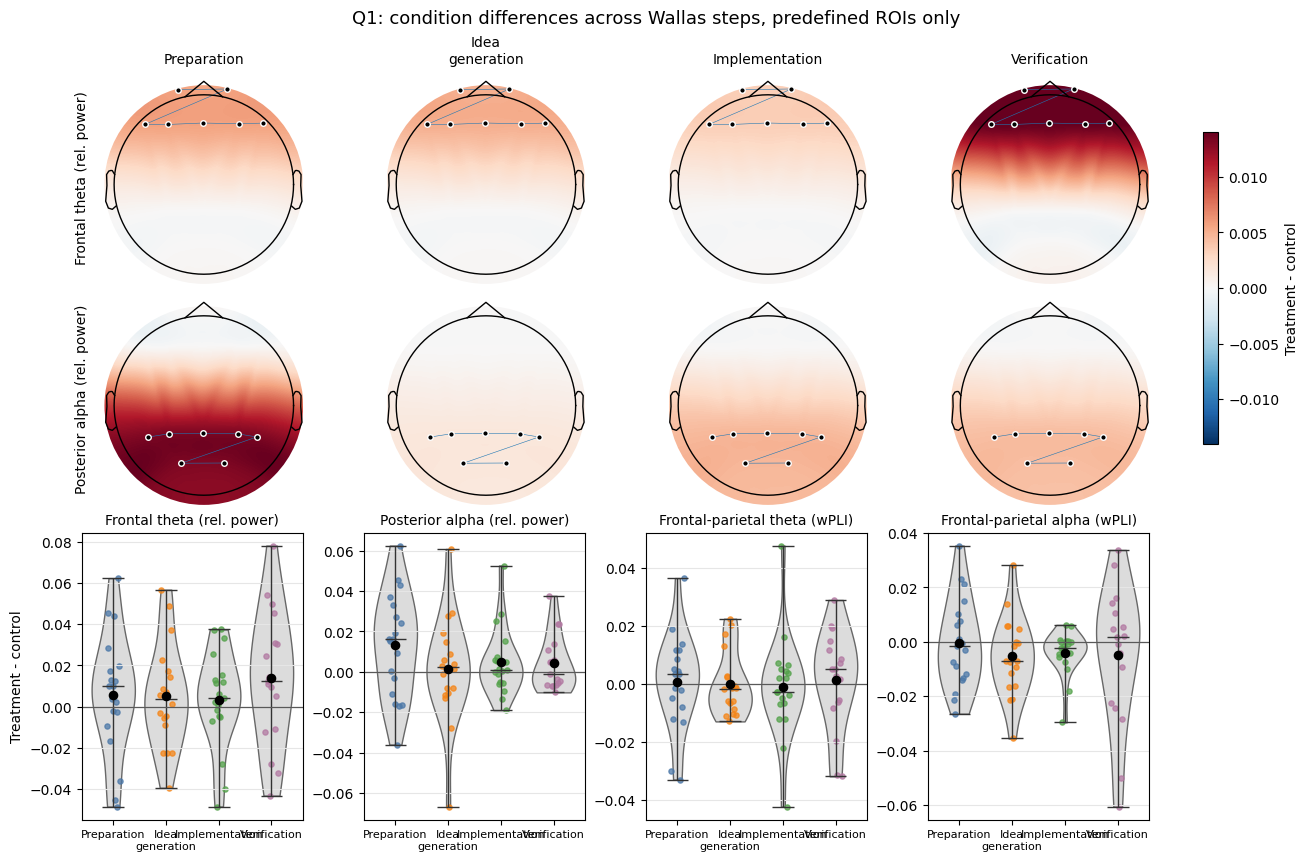

In [15]:
q1_diff_long = pd.DataFrame([
    {'Pid': pid, 'feature': feat, 'step': step, 'treatment_minus_control': val}
    for feat in BASELINE_DELTA_FEATURES for step in STEPS
    for pid, val in (wide[(feat, 'treatment', step)].dropna() - wide[(feat, 'control', step)].dropna()).dropna().items()
])

TOPO_FEATURES = [('Frontal theta (rel. power) vs baseline', FRONTAL),
                 ('Posterior alpha (rel. power) vs baseline', POSTERIOR)]
topo_info = mne.create_info(CHANNELS, sfreq=300, ch_types='eeg')
topo_info.set_montage(mne.channels.make_standard_montage('standard_1020'), on_missing='ignore')
power_lim = max(1e-6, np.nanmax([abs(condition_change.loc[condition_change.feature == f, 'mean_treatment_minus_control']).max()
                                  for f, _ in TOPO_FEATURES]))

fig = plt.figure(figsize=(13, 8.5), constrained_layout=True)
gs = fig.add_gridspec(3, len(STEPS), height_ratios=[1, 1, 1.35])
topo_axes, last_im = [], None
for r, (feat, roi_chs) in enumerate(TOPO_FEATURES):
    roi_idx = [CHANNELS.index(ch) for ch in roi_chs if ch in CHANNELS]
    for c, step in enumerate(STEPS):
        ax = fig.add_subplot(gs[r, c]); topo_axes.append(ax)
        val = condition_change.query('feature == @feat and step == @step').iloc[0].mean_treatment_minus_control
        vals, mask = np.zeros(len(CHANNELS)), np.zeros(len(CHANNELS), bool)
        vals[roi_idx], mask[roi_idx] = val, True
        last_im, _ = mne.viz.plot_topomap(vals, topo_info, axes=ax, show=False, cmap='RdBu_r',
                                          vlim=(-power_lim, power_lim), contours=0, sensors=False,
                                          mask=mask, mask_params=dict(marker='o', markerfacecolor='black',
                                                                      markeredgecolor='white', linewidth=0.4, markersize=4))
        if r == 0: ax.set_title(step.replace(' ', '\n'), fontsize=10)
        if c == 0: ax.text(-0.08, 0.5, feat.replace(' vs baseline', ''), transform=ax.transAxes,
                           ha='right', va='center', rotation=90, fontsize=10)
fig.colorbar(last_im, ax=topo_axes, shrink=0.72, label='Treatment - control')

for i, feat in enumerate(BASELINE_DELTA_FEATURES):
    ax = fig.add_subplot(gs[2, i])
    data = [q1_diff_long.query('feature == @feat and step == @step').treatment_minus_control.dropna().to_numpy()
            for step in STEPS]
    parts = ax.violinplot(data, positions=np.arange(len(STEPS)), showmedians=True, widths=0.82)
    for body in parts['bodies']:
        body.set(facecolor='#D9D9D9', edgecolor='0.35', alpha=0.9)
    for k in ['cmedians', 'cbars', 'cmins', 'cmaxes']:
        parts[k].set(color='0.2', linewidth=1)
    for j, vals in enumerate(data):
        if len(vals):
            ax.scatter(j + np.linspace(-0.12, 0.12, len(vals)), vals, s=14, color=STEP_COLORS[STEPS[j]], alpha=0.75)
            ax.scatter(j, np.mean(vals), s=35, color='black', zorder=4)
    ax.axhline(0, color='0.35', lw=0.9)
    ax.set_xticks(range(len(STEPS)), [s.replace(' ', '\n') for s in STEPS], fontsize=8)
    ax.set_title(feat.replace(' vs baseline', ''), fontsize=10)
    ax.grid(axis='y', color='0.9', linewidth=0.8)
    if i == 0: ax.set_ylabel('Treatment - control')
fig.suptitle('Q1: condition differences across Wallas steps, predefined ROIs only', fontsize=13)
plt.show()


## 11. Question 1 statistical tests: Wallas steps only


In [16]:
from scipy import stats
import statsmodels.formula.api as smf


def bh_fdr(p_values):
    p = np.asarray(p_values, float)
    out = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    if ok.any():
        pv, order = p[ok], np.argsort(p[ok])
        ranked = pv[order] * len(pv) / np.arange(1, len(pv) + 1)
        adj = np.empty(len(pv)); adj[order] = np.clip(np.minimum.accumulate(ranked[::-1])[::-1], 0, 1)
        out[ok] = adj
    return out


def fit_mixedlm(formula, d):
    return smf.mixedlm(formula, d, groups=d['Pid']).fit(reml=False, method='powell', maxiter=500, disp=False)


def lr_test(full, reduced):
    lr = max(0.0, 2 * (full.llf - reduced.llf))
    df = max(1, len(full.fe_params) - len(reduced.fe_params))
    return lr, df, float(stats.chi2.sf(lr, df))


def display_fdr_significant(df, q_col, title):
    sig = df[df[q_col] < 0.05].sort_values(q_col)
    print(title)
    print('No FDR-significant results.' if sig.empty else '')
    if not sig.empty: display(sig)


def paired_condition_tests(wide_df, features, steps=None):
    rows = []
    iterator = [(feat, step) for feat in features for step in (steps or [None])]
    for feat, step in iterator:
        c = wide_df[(feat, 'control') if step is None else (feat, 'control', step)]
        t = wide_df[(feat, 'treatment') if step is None else (feat, 'treatment', step)]
        m, label = c.notna() & t.notna(), {'feature': feat, **({} if step is None else {'step': step})}
        diff = t[m] - c[m]
        res = stats.wilcoxon(t[m], c[m], zero_method='wilcox', method='exact') if len(diff) and not np.allclose(diff, 0) else None
        rows.append({**label, 'n_subjects': int(m.sum()),
                     'mean_control_vs_baseline': float(c[m].mean()) if m.any() else np.nan,
                     'mean_treatment_vs_baseline': float(t[m].mean()) if m.any() else np.nan,
                     'mean_treatment_minus_control': float(diff.mean()) if len(diff) else np.nan,
                     'median_treatment_minus_control': float(diff.median()) if len(diff) else np.nan,
                     'wilcoxon_w': np.nan if res is None else float(res.statistic),
                     'p': np.nan if res is None else float(res.pvalue)})
    out = pd.DataFrame(rows); out['p_fdr_all'] = bh_fdr(out['p'])
    if steps is not None:
        out['p_fdr_within_feature'] = out.groupby('feature')['p'].transform(bh_fdr)
    return out


def mixed_effect_tests(df, features, value_col_by_feature=lambda f: f):
    rows = []
    for feat in features:
        d = df.dropna(subset=[value_col_by_feature(feat), 'condition', 'step', 'Pid']).copy()
        d = d[d.step.isin(STEPS)].assign(y=lambda x: x[value_col_by_feature(feat)],
                                         Pid=lambda x: x.Pid.astype(str),
                                         condition=lambda x: pd.Categorical(x.condition, ['control', 'treatment']),
                                         step=lambda x: pd.Categorical(x.step, STEPS))
        base = {'feature': feat, 'n_rows': len(d), 'n_subjects': d.Pid.nunique()}
        try:
            full = fit_mixedlm('y ~ C(condition) * C(step)', d)
            models = {'condition_or_condition_by_step': fit_mixedlm('y ~ C(step)', d),
                      'wallas_step_or_interaction': fit_mixedlm('y ~ C(condition)', d),
                      'condition_x_step': fit_mixedlm('y ~ C(condition) + C(step)', d)}
            for effect, reduced in models.items():
                lr, df_lr, p_lr = lr_test(full, reduced)
                rows.append({**base, 'test': 'mixedlm_likelihood_ratio', 'effect': effect,
                             'lr_chi2': lr, 'df': df_lr, 'p': p_lr, 'status': 'ok'})
        except Exception as err:
            rows.append({**base, 'test': 'mixedlm_likelihood_ratio', 'effect': 'model_failed',
                         'lr_chi2': np.nan, 'df': np.nan, 'p': np.nan, 'status': str(err)})
    out = pd.DataFrame(rows); out['p_fdr_all'] = bh_fdr(out['p'])
    return out

q1_all_steps = unit_table(['Pid', 'condition']).merge(baseline_features[['Pid'] + FEATURES], on='Pid', how='left', suffixes=('', '_baseline'))
for feat in FEATURES:
    q1_all_steps[f'{feat} vs baseline'] = q1_all_steps[feat] - q1_all_steps[f'{feat}_baseline']

q1_all_steps_tests = paired_condition_tests(q1_all_steps.pivot(index='Pid', columns='condition'), BASELINE_DELTA_FEATURES)
q1_model_tests = mixed_effect_tests(cells_bc, BASELINE_DELTA_FEATURES)
q1_step_tests = paired_condition_tests(wide, BASELINE_DELTA_FEATURES, STEPS)

display_fdr_significant(q1_all_steps_tests, 'p_fdr_all', 'Q1 all Wallas steps combined:')
display_fdr_significant(q1_model_tests, 'p_fdr_all', 'Q1 mixed-model tests:')
display_fdr_significant(q1_step_tests, 'p_fdr_all', 'Q1 paired tests within each Wallas step:')


/Users/athenasaghi/anaconda3/envs/CreativityProject/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/athenasaghi/anaconda3/envs/CreativityProject/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/athenasaghi/anaconda3/envs/CreativityProject/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/athenasaghi/anaconda3/envs/CreativityProject/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/a

Q1 all Wallas steps combined:
No FDR-significant results.
Q1 mixed-model tests:
No FDR-significant results.
Q1 paired tests within each Wallas step:
No FDR-significant results.


/Users/athenasaghi/anaconda3/envs/CreativityProject/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/athenasaghi/anaconda3/envs/CreativityProject/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/athenasaghi/anaconda3/envs/CreativityProject/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/athenasaghi/anaconda3/envs/CreativityProject/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/a

## 12. Question 1 dDTF tests: Wallas steps only

ROI-level dDTF (frontal, parietal, occipital) across Wallas-labelled segments, Unassisted vs LLM-assisted. 4-s windows resampled to 128 Hz; MVAR order chosen by AIC on a random sample of 1,000 windows (BIC reported alongside); windows with an unstable model fit are excluded. Test per pathway: mixed-model likelihood-ratio test of condition + condition x step against step alone (participant random intercept), FDR across the 12 pathways.


In [ ]:
from collections import defaultdict
from scipy import signal, stats
import statsmodels.formula.api as smf
import importlib.util, sys

WHOLE_SESSION_DIR = PROJECT / 'Whole Session'
if str(WHOLE_SESSION_DIR) not in sys.path: sys.path.insert(0, str(WHOLE_SESSION_DIR))
spec = importlib.util.spec_from_file_location('whole_session_ddtf', WHOLE_SESSION_DIR / 'wholesession_ddtf.py')
whole_session_ddtf = importlib.util.module_from_spec(spec); spec.loader.exec_module(whole_session_ddtf)

# Parameters and rationale
# - 3 ROIs (frontal, parietal, occipital; channel means): keeps the MVAR model low-dimensional for the data per window.
# - 4-s non-overlapping windows inside Wallas segments, never crossing rejected data: approximate stationarity vs stable fits.
# - resample 300 -> 128 Hz: keeps 1-50 Hz (Nyquist 64 Hz) so few lags span physiologically relevant delays.
# - MVAR order chosen by AIC (standard for DTF/dDTF) on a random window sample, not fixed a priori; BIC reported alongside.
# - windows whose fitted model is unstable (companion eigenvalue |lambda| >= 1) are excluded: their transfer function is invalid.
# - dDTF (DTF x partial coherence) suppresses indirect flows; theta 4-8 Hz and alpha 8-13 Hz.
DDTF_WINDOW_SEC, DDTF_RESAMPLE_SFREQ = 4.0, 128.0
DDTF_ORDERS, ORDER_SAMPLE, ORDER_SEED = range(1, 21), 1000, 42
DDTF_BANDS = {'Theta': (4.0, 8.0), 'Alpha': (8.0, 13.0)}
DDTF_FREQS = np.arange(1.0, 50.0 + 0.5, 0.5)
DDTF_BAND_MASKS = {b: (DDTF_FREQS >= lo) & (DDTF_FREQS < hi) for b, (lo, hi) in DDTF_BANDS.items()}


def ddtf_starts(c0, c1, cuts, n):
    edges = [c0] + [b for b in cuts if c0 < b < c1] + [c1]
    return [s for a, b in zip(edges[:-1], edges[1:]) for s in range(a, b - n + 1, n)]


def normalise_window(x):
    """Same preprocessing ddtf_window applies before fitting: detrend, demean, unit variance."""
    x = signal.detrend(x, axis=1, type='linear'); x = x - x.mean(axis=1, keepdims=True)
    return x / x.std(axis=1, keepdims=True)


def information_criteria(x, order):
    """(AIC, BIC) of a least-squares MVAR fit: ln det Sigma + penalty * order * k^2 / N."""
    a, sigma, _ = whole_session_ddtf.fit_mvar(x, order)
    if a is None: return np.nan, np.nan
    k, n_eff = x.shape[0], x.shape[1] - order
    logdet = np.linalg.slogdet(sigma * (n_eff - 1) / n_eff)[1]  # ML covariance
    n_par = order * k * k
    return logdet + 2 * n_par / n_eff, logdet + np.log(n_eff) * n_par / n_eff


# 1. collect every resampled ROI window with its labels
windows = []
for key in sorted(eeg, key=lambda k: (int(k[0][1:]), k[1], k[2])):
    pid, cond, task = key
    segs = segments.query('Pid == @pid and condition == @cond and task == @task and wallas_step in @STEPS')
    if segs.empty: continue
    raw = mne.io.read_raw_eeglab(str(CLEAN_DIR / eeg[key]['file']), preload=True, verbose=False).pick(CHANNELS)
    data, roi_names = whole_session_ddtf.roi_series(raw, CHANNELS)
    sfreq, n = float(raw.info['sfreq']), int(round(DDTF_WINDOW_SEC * raw.info['sfreq']))
    cuts = sorted({int(round(raw_to_clean(c0, eeg[key]['cuts']) * sfreq)) for c0, _ in eeg[key]['cuts']})
    for _, seg in segs.iterrows():
        for start in ddtf_starts(int(seg.clean_start_sample), int(seg.clean_end_sample), cuts, n):
            x = signal.resample_poly(data[:, start:start + n], int(DDTF_RESAMPLE_SFREQ), int(round(sfreq)), axis=1)
            windows.append((pid, cond, task, seg.wallas_step, x))

# 2. model order: minimise mean AIC over a random sample of windows
rng = np.random.default_rng(ORDER_SEED)
sample = [normalise_window(windows[i][4]) for i in rng.choice(len(windows), size=min(ORDER_SAMPLE, len(windows)), replace=False)]
ic = np.array([[information_criteria(x, p) for p in DDTF_ORDERS] for x in sample])  # windows x orders x (AIC, BIC)
q1_ddtf_order_selection = pd.DataFrame({'order': list(DDTF_ORDERS), 'mean_AIC': np.nanmean(ic[:, :, 0], axis=0), 'mean_BIC': np.nanmean(ic[:, :, 1], axis=0)})
DDTF_ORDER = int(q1_ddtf_order_selection.loc[q1_ddtf_order_selection.mean_AIC.idxmin(), 'order'])
bic_order = int(q1_ddtf_order_selection.loc[q1_ddtf_order_selection.mean_BIC.idxmin(), 'order'])
print(f'MVAR order: AIC -> {DDTF_ORDER} (used), BIC -> {bic_order} ({len(sample)} sampled windows)')

# 3. dDTF per window; unstable fits excluded
acc, counts, coverage = defaultdict(float), defaultdict(int), defaultdict(lambda: {'n_windows': 0, 'n_unstable_excluded': 0})
for pid, cond, task, step, x in windows:
    vals, stable = whole_session_ddtf.ddtf_window(x, DDTF_RESAMPLE_SFREQ, DDTF_ORDER, DDTF_FREQS, DDTF_BAND_MASKS)
    if vals is None: continue
    if not stable:
        coverage[pid, cond, task]['n_unstable_excluded'] += 1; continue
    coverage[pid, cond, task]['n_windows'] += 1
    for band in DDTF_BANDS:
        for src_i, source in enumerate(roi_names):
            for tgt_i, target in enumerate(roi_names):
                if src_i == tgt_i: continue
                unit = (pid, cond, step, f'{band} {source}->{target} dDTF')
                acc[unit] += float(vals[band][tgt_i, src_i]); counts[unit] += 1

q1_ddtf_unit = pd.DataFrame([
    {'Pid': k[0], 'condition': k[1], 'step': k[2], 'feature': k[3], 'value': v / counts[k], 'n_windows': counts[k]}
    for k, v in acc.items()
])
q1_ddtf_coverage = pd.DataFrame([{'Pid': p, 'condition': c, 'task': t, **v} for (p, c, t), v in coverage.items()])
del windows


def _bh_fdr(p_values):
    p = np.asarray(p_values, float); out = np.full(p.shape, np.nan); ok = np.isfinite(p)
    if ok.any():
        pv, order = p[ok], np.argsort(p[ok])
        ranked = pv[order] * len(pv) / np.arange(1, len(pv) + 1)
        adj = np.empty(len(pv)); adj[order] = np.clip(np.minimum.accumulate(ranked[::-1])[::-1], 0, 1); out[ok] = adj
    return out


def _show_sig(df, q_col, title):
    sig = df[df[q_col] < 0.05].sort_values(q_col)
    print(title); print('No FDR-significant results.' if sig.empty else '')
    if not sig.empty: display(sig)


def _ddtf_condition_test(feature, d):
    # mixed model, participant random intercept, ML fit; LR test of condition + condition x step against step alone
    d = d.dropna(subset=['value', 'condition', 'step', 'Pid']).copy()
    d = d.assign(Pid=d.Pid.astype(str), condition=pd.Categorical(d.condition, ['control', 'treatment']), step=pd.Categorical(d.step, STEPS))
    row = {'feature': feature, 'n_rows': len(d), 'n_subjects': d.Pid.nunique()}
    try:
        fit = lambda f: smf.mixedlm(f, d, groups=d.Pid).fit(reml=False, method='powell', maxiter=500, disp=False)
        full, reduced = fit('value ~ C(condition) * C(step)'), fit('value ~ C(step)')
        lr = max(0.0, 2 * (full.llf - reduced.llf)); df_lr = max(1, len(full.fe_params) - len(reduced.fe_params))
        row.update(test='mixedlm_likelihood_ratio', effect='condition_or_condition_by_step', lr_chi2=lr, df=df_lr, p=float(stats.chi2.sf(lr, df_lr)), status='ok')
    except Exception as err:
        row.update(test='mixedlm_likelihood_ratio', effect='condition_or_condition_by_step', lr_chi2=np.nan, df=np.nan, p=np.nan, status=str(err))
    return row

q1_ddtf_tests = pd.DataFrame([_ddtf_condition_test(f, d) for f, d in q1_ddtf_unit.groupby('feature')])
q1_ddtf_tests['p_fdr_all'] = _bh_fdr(q1_ddtf_tests['p'])
q1_ddtf_tests['mean_control'] = q1_ddtf_tests.feature.map(q1_ddtf_unit.query("condition == 'control'").groupby('feature').value.mean())
q1_ddtf_tests['mean_treatment'] = q1_ddtf_tests.feature.map(q1_ddtf_unit.query("condition == 'treatment'").groupby('feature').value.mean())
q1_ddtf_tests['mean_treatment_minus_control'] = q1_ddtf_tests['mean_treatment'] - q1_ddtf_tests['mean_control']

_show_sig(q1_ddtf_tests, 'p_fdr_all', 'Q1 Wallas-only dDTF condition-related tests:')
print('dDTF windows used:', int(q1_ddtf_coverage.n_windows.sum()), '| unstable excluded:', int(q1_ddtf_coverage.n_unstable_excluded.sum()))

In [18]:
rows = []
for feat in q1_ddtf_tests.query('p_fdr_all < 0.05').feature:
    for step in STEPS:
        w = (q1_ddtf_unit.query('feature == @feat and step == @step')
             .pivot(index='Pid', columns='condition', values='value').reindex(columns=CONDITIONS).dropna())
        d = w['treatment'] - w['control']
        p = stats.wilcoxon(d).pvalue if len(d) and not np.allclose(d, 0) else np.nan
        rows.append(dict(feature=feat, step=step, n_subjects=len(d), mean_control=w['control'].mean(),
                         mean_treatment=w['treatment'].mean(), mean_treatment_minus_control=d.mean(), p=p))

q1_ddtf_posthoc = pd.DataFrame(rows)
q1_ddtf_posthoc['p_fdr_all'] = _bh_fdr(q1_ddtf_posthoc.p)
q1_ddtf_posthoc_sig = q1_ddtf_posthoc[q1_ddtf_posthoc.p_fdr_all < 0.05].sort_values('p_fdr_all')
print('Q1 dDTF post-hoc significant Wallas steps only:')
print('No FDR-significant post-hoc steps.' if q1_ddtf_posthoc_sig.empty else '')
if not q1_ddtf_posthoc_sig.empty: display(q1_ddtf_posthoc_sig)

Q1 dDTF post-hoc significant Wallas steps only:
No FDR-significant post-hoc steps.


In [ ]:
# Q1 dDTF figures from the results above (FDR-significant pathways bold + starred, the rest dashed):
# Kosmyna-style glass head and fsaverage cortex, saved to wallas_analysis/figures/ and shown here.
# The cortex render takes about two minutes.
import kosmyna_style_figures as kfig
from IPython.display import Image

for surface, name in (('head', 'q1_ddtf_kosmyna_networks'), ('brain', 'q1_ddtf_brain_networks')):
    kfig.plot_ddtf_networks(q1_ddtf_tests, 'q1', surface)
    display(Image(filename=str(PROJECT / 'wallas_analysis' / 'figures' / f'{name}.png'), width=900))

## 13. Question 2: AI use vs non-AI work over session progress

Treatment sessions only. `inquire` and `adoptCopilot` are combined into one `AI interaction` state; all other coded treatment epochs are `No AI interaction`. Features are corrected against each participant's baseline file and binned by normalized session progress (`PROGRESS_BINS`).

Test: sign-flip cluster permutation across adjacent progress bins on per-participant AI - No AI differences, FDR across all clusters.


In [19]:
from scipy import stats

def dwpli_from_epoch_rows(d, name):
    s, s2, a = d[f'{name} sum_imag'].sum(), d[f'{name} sum_imag_sq'].sum(), d[f'{name} sum_abs_imag'].sum()
    den = a ** 2 - s2
    return np.nan if not np.isfinite(den) or den == 0 else (s ** 2 - s2) / den


def summarize_epoch_group(d):
    row = {feat: d[feat].mean() for feat in POWER_FEATURES}
    row.update({feat: dwpli_from_epoch_rows(d, feat) for feat in WPLI_FEATURES})
    row['n_epochs'] = len(d)
    return pd.Series(row)


AI_ACTIONS = {'inquire', 'adoptCopilot'}
PROGRESS_BINS = np.linspace(0, 1, 11)
PROGRESS_LABELS = ((PROGRESS_BINS[:-1] + PROGRESS_BINS[1:]) / 2 * 100).round(0)
coding_actions = sheet[['_row', 'Action Coding']].rename(columns={'_row': 'coding_row', 'Action Coding': 'action'})
session_durations = pd.DataFrame([{'Pid': p, 'condition': c, 'task': t, 'clean_sec': e['clean_sec']} for (p, c, t), e in eeg.items()])

treatment_epochs = (epochs.query("condition == 'treatment'")
    .merge(coding_actions, on='coding_row', how='left')
    .merge(session_durations, on=['Pid', 'condition', 'task'], how='left'))
treatment_epochs = treatment_epochs.assign(
    session=lambda d: d.Pid + '_' + d.task,
    interaction_state=lambda d: np.where(d.action.isin(AI_ACTIONS), 'AI interaction', 'No AI interaction'),
    progress=lambda d: d.epoch_mid_clean_sec / d.clean_sec,
    progress_bin_pct=lambda d: pd.cut(d.progress.clip(0, 1), PROGRESS_BINS, labels=PROGRESS_LABELS, include_lowest=True).astype(float),
)
unit_time = (treatment_epochs.groupby(['Pid', 'task', 'session', 'interaction_state', 'progress_bin_pct'])
             .apply(summarize_epoch_group).reset_index()
             .merge(baseline_features[['Pid'] + FEATURES], on='Pid', how='left', suffixes=('', '_baseline')))
Q2_DELTA_FEATURES = [f'{feat} vs baseline' for feat in FEATURES]
for feat, col in zip(FEATURES, Q2_DELTA_FEATURES):
    unit_time[col] = unit_time[feat] - unit_time[f'{feat}_baseline']

# AI - No AI within each session x progress bin, then averaged per participant and bin
paired_wide = unit_time.pivot_table(index=['Pid', 'session', 'progress_bin_pct'], columns='interaction_state',
                                    values=Q2_DELTA_FEATURES, aggfunc='mean')
pid_bin = pd.concat([
    (paired_wide[(f, 'AI interaction')] - paired_wide[(f, 'No AI interaction')]).dropna().reset_index(name='AI_minus_NoAI').assign(feature=f)
    for f in Q2_DELTA_FEATURES if (f, 'AI interaction') in paired_wide and (f, 'No AI interaction') in paired_wide
], ignore_index=True).groupby(['Pid', 'progress_bin_pct', 'feature'], as_index=False).AI_minus_NoAI.mean()


def one_sample_t(vals):
    vals = np.asarray(vals, float); vals = vals[np.isfinite(vals)]
    return np.nan if len(vals) < 3 or np.nanstd(vals, ddof=1) == 0 else stats.ttest_1samp(vals, 0.0).statistic


def cluster_stats_from_t(t_vals, threshold):
    """[(start, end, sum |t|)] for each run of adjacent bins with |t| >= threshold."""
    clusters, start = [], None
    for i, t in enumerate(t_vals):
        active = np.isfinite(t) and abs(t) >= threshold
        if active and start is None: start = i
        if start is not None and (not active or i == len(t_vals) - 1):
            end = i if active and i == len(t_vals) - 1 else i - 1
            clusters.append((start, end, float(np.nansum(np.abs(t_vals[start:end + 1]))))); start = None
    return clusters


def cluster_permutation_test(feature, n_perm=500, seed=42, cluster_alpha=0.05):
    d = pid_bin.query('feature == @feature')
    progress, pids = np.array(sorted(d.progress_bin_pct.dropna().unique()), float), sorted(d.Pid.unique(), key=lambda p: int(str(p)[1:]))
    arr = d.pivot(index='Pid', columns='progress_bin_pct', values='AI_minus_NoAI').reindex(index=pids, columns=progress).to_numpy(float)
    n_by_bin, t_bins = np.sum(np.isfinite(arr), axis=0), lambda a: np.array([one_sample_t(a[:, j]) for j in range(a.shape[1])])
    t_obs = t_bins(arr)
    threshold = stats.t.ppf(1 - cluster_alpha / 2, df=max(int(np.nanmax(n_by_bin)) - 1, 1))
    rng = np.random.default_rng(seed)  # null: sign-flip each participant's whole timecourse
    max_stats = np.array([max([c[2] for c in cluster_stats_from_t(t_bins(arr * rng.choice([-1.0, 1.0], size=arr.shape[0])[:, None]), threshold)], default=0.0)
                          for _ in range(n_perm)])
    return [dict(feature=feature, cluster_id=i, start_progress_pct=progress[s], end_progress_pct=progress[e],
                 cluster_stat_sum_abs_t=stat, cluster_p=(1 + np.sum(max_stats >= stat)) / (n_perm + 1),
                 max_abs_t_in_cluster=float(np.nanmax(np.abs(t_obs[s:e + 1]))), mean_AI_minus_NoAI_in_cluster=float(np.nanmean(arr[:, s:e + 1])),
                 min_n_subjects_in_cluster=int(np.nanmin(n_by_bin[s:e + 1])))
            for i, (s, e, stat) in enumerate(cluster_stats_from_t(t_obs, threshold), 1)]


q2_cluster_tests = pd.DataFrame([r for f in Q2_DELTA_FEATURES for r in cluster_permutation_test(f)])
if len(q2_cluster_tests):
    q2_cluster_tests['cluster_p_fdr'] = stats.false_discovery_control(q2_cluster_tests.cluster_p.to_numpy())
print('Temporal cluster permutation tests')
display(q2_cluster_tests.sort_values('cluster_p') if len(q2_cluster_tests) else 'No clusters above threshold.')

Temporal cluster permutation tests


,feature,cluster_id,start_progress_pct,end_progress_pct,cluster_stat_sum_abs_t,cluster_p,max_abs_t_in_cluster,mean_AI_minus_NoAI_in_cluster,min_n_subjects_in_cluster,cluster_p_fdr
1,Posterior alpha (rel. power) vs baseline,1,35.0,45.0,6.326484,0.009980,3.218818,0.006630,9,0.039920
2,Posterior alpha (rel. power) vs baseline,2,65.0,75.0,5.083922,0.019960,2.599200,-0.007768,12,0.039920
3,Frontal-parietal theta (wPLI) vs baseline,1,5.0,5.0,4.714784,0.057884,4.714784,0.006572,5,0.077179
0,Frontal theta (rel. power) vs baseline,1,5.0,5.0,3.561408,0.101796,3.561408,0.010317,5,0.101796


## 14. Question 2 dDTF tests: Wallas steps only

Treatment sessions only. Same ROI dDTF windows and model as section 12, with the Q2 interaction state (`AI interaction` = `inquire` / `adoptCopilot`, else `No AI interaction`) in place of condition: likelihood-ratio test of state + state x step against step alone, participant random intercept, FDR across all pathways.


In [21]:
Q2_STATES = ['No AI interaction', 'AI interaction']
segment_action = coding_actions.set_index('coding_row')['action']

acc, counts, coverage = defaultdict(float), defaultdict(int), []
for key in sorted(eeg, key=lambda k: (int(k[0][1:]), k[1], k[2])):
    pid, cond, task = key
    if cond != 'treatment': continue
    segs = segments.query('Pid == @pid and condition == @cond and task == @task and wallas_step in @STEPS').copy()
    if segs.empty: continue
    segs['state'] = np.where(segs.coding_row.map(segment_action).isin(AI_ACTIONS), 'AI interaction', 'No AI interaction')
    raw = mne.io.read_raw_eeglab(str(CLEAN_DIR / eeg[key]['file']), preload=True, verbose=False).pick(CHANNELS)
    raw._data = raw.get_data() - baseline_offsets_for_pid(pid)[:, None]
    data, roi_names = whole_session_ddtf.roi_series(raw, CHANNELS)
    sfreq, n = float(raw.info['sfreq']), int(round(DDTF_WINDOW_SEC * raw.info['sfreq']))
    cuts = sorted({int(round(raw_to_clean(c0, eeg[key]['cuts']) * sfreq)) for c0, _ in eeg[key]['cuts']})
    n_win = dict.fromkeys(Q2_STATES, 0)
    for _, seg in segs.iterrows():
        for start in ddtf_starts(int(seg.clean_start_sample), int(seg.clean_end_sample), cuts, n):
            x = signal.resample_poly(data[:, start:start + n], int(DDTF_RESAMPLE_SFREQ), int(round(sfreq)), axis=1)
            vals, stable = whole_session_ddtf.ddtf_window(x, DDTF_RESAMPLE_SFREQ, DDTF_ORDER, DDTF_FREQS, DDTF_BAND_MASKS)
            if vals is None: continue
            n_win[seg.state] += 1
            for band in DDTF_BANDS:
                for src_i, source in enumerate(roi_names):
                    for tgt_i, target in enumerate(roi_names):
                        if src_i == tgt_i: continue
                        unit = (pid, seg.state, seg.wallas_step, f'{band} {source}->{target} dDTF')
                        acc[unit] += float(vals[band][tgt_i, src_i]); counts[unit] += 1
    coverage.append({'Pid': pid, 'task': task, **{f'n_windows {st}': v for st, v in n_win.items()}})

q2_ddtf_unit = pd.DataFrame([
    {'Pid': k[0], 'state': k[1], 'step': k[2], 'feature': k[3], 'value': v / counts[k], 'n_windows': counts[k]}
    for k, v in acc.items()
])
q2_ddtf_coverage = pd.DataFrame(coverage)


def _ddtf_state_test(feature, d):
    d = d.dropna(subset=['value', 'state', 'step', 'Pid']).copy()
    d = d.assign(Pid=d.Pid.astype(str), state=pd.Categorical(d.state, Q2_STATES), step=pd.Categorical(d.step, STEPS))
    row = {'feature': feature, 'n_rows': len(d), 'n_subjects': d.Pid.nunique()}
    try:
        fit = lambda f: smf.mixedlm(f, d, groups=d.Pid).fit(reml=False, method='powell', maxiter=500, disp=False)
        full, reduced = fit('value ~ C(state) * C(step)'), fit('value ~ C(step)')
        lr = max(0.0, 2 * (full.llf - reduced.llf)); df_lr = max(1, len(full.fe_params) - len(reduced.fe_params))
        row.update(test='mixedlm_likelihood_ratio', effect='state_or_state_by_step', lr_chi2=lr, df=df_lr, p=float(stats.chi2.sf(lr, df_lr)), status='ok')
    except Exception as err:
        row.update(test='mixedlm_likelihood_ratio', effect='state_or_state_by_step', lr_chi2=np.nan, df=np.nan, p=np.nan, status=str(err))
    return row

q2_ddtf_tests = pd.DataFrame([_ddtf_state_test(f, d) for f, d in q2_ddtf_unit.groupby('feature')])
q2_ddtf_tests['p_fdr_all'] = _bh_fdr(q2_ddtf_tests['p'])
q2_state_means = q2_ddtf_unit.groupby(['feature', 'state']).value.mean().unstack()
q2_ddtf_tests['mean_no_ai'] = q2_ddtf_tests.feature.map(q2_state_means['No AI interaction'])
q2_ddtf_tests['mean_ai'] = q2_ddtf_tests.feature.map(q2_state_means['AI interaction'])
q2_ddtf_tests['mean_ai_minus_no_ai'] = q2_ddtf_tests['mean_ai'] - q2_ddtf_tests['mean_no_ai']

_show_sig(q2_ddtf_tests, 'p_fdr_all', 'Q2 Wallas-only dDTF state-related tests:')
print('dDTF windows:', q2_ddtf_coverage.drop(columns=['Pid', 'task']).sum().to_dict())


Q2 Wallas-only dDTF state-related tests:
No FDR-significant results.
dDTF windows: {'n_windows No AI interaction': 4824, 'n_windows AI interaction': 1133}


## 15. Question 2 posterior alpha per channel, by Wallas step

Relative alpha (8-13 / 1-50 Hz) for all 19 channels, computed like the section 8 epoch features (2-s Hann epochs within Wallas segments) and corrected against each participant's baseline file. Restricted to the two session windows where the section 13 posterior-alpha cluster test was significant (progress bins centred 35-45% and 65-75%, i.e. 30-50% and 60-80% of the session). As in that test, AI - No AI differences are taken within session x progress bin, then averaged per participant.

Posterior ROI test (section 16): mean of P7, P3, Pz, P4, P8, O1, O2; Wilcoxon signed-rank of the per-participant differences; FDR across every step x window cell with at least 3 participants having both states.


In [22]:
ALL_CHANNELS = ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8',
                'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2']
Q2_TOPO_WINDOWS = {'35-45%': (0.3, 0.5), '65-75%': (0.6, 0.8)}


def rel_alpha_per_channel(X, sfreq):
    """X: (epochs, channels, samples) -> relative alpha per epoch and channel."""
    n = X.shape[2]; freqs = np.fft.rfftfreq(n, 1 / sfreq)
    fsel = (freqs >= TOTAL_BAND[0]) & (freqs < TOTAL_BAND[1])
    alpha = (freqs[fsel] >= BANDS['Alpha'][0]) & (freqs[fsel] < BANDS['Alpha'][1])
    psd = np.abs(np.fft.rfft((X - X.mean(axis=2, keepdims=True)) * np.hanning(n), axis=2)[:, :, fsel]) ** 2
    return psd[:, :, alpha].sum(axis=2) / psd.sum(axis=2)


def baseline_rel_alpha(pid):
    """Per-channel baseline relative alpha from the same source as load_subject_baseline_raw."""
    path = baseline_path_for_pid(pid)
    if path:
        raw_b = mne.io.read_raw_eeglab(str(path), preload=True, verbose=False).pick(ALL_CHANNELS)
    else:
        key = sorted(k for k in eeg if k[0] == pid and k[1] == 'control')[0]
        raw_b, _ = baseline_from_task_start(
            mne.io.read_raw_eeglab(str(CLEAN_DIR / eeg[key]['file']), preload=True, verbose=False).pick(ALL_CHANNELS), pid)
    ep = mne.make_fixed_length_epochs(raw_b, duration=EPOCH_SEC, preload=True, reject_by_annotation=True, verbose=False)
    return rel_alpha_per_channel(ep.get_data() * 1e6, raw_b.info['sfreq']).mean(axis=0)


topo_rows = []
for key in sorted(eeg, key=lambda k: (int(k[0][1:]), k[1], k[2])):
    pid, cond, task = key
    if cond != 'treatment': continue
    e = eeg[key]; sfreq = e['sfreq']; n = int(round(EPOCH_SEC * sfreq))
    cut_samples = sorted({int(round(raw_to_clean(c0, e['cuts']) * sfreq)) for c0, _ in e['cuts']})
    data = mne.io.read_raw_eeglab(str(CLEAN_DIR / e['file']), preload=True, verbose=False).pick(ALL_CHANNELS).get_data() * 1e6
    base = baseline_rel_alpha(pid)
    segs = segments.query('Pid == @pid and condition == @cond and task == @task and wallas_step in @STEPS')
    for _, seg in segs.iterrows():
        starts = epoch_starts(int(seg.clean_start_sample), int(seg.clean_end_sample), cut_samples, n)
        if not starts: continue
        rel = rel_alpha_per_channel(np.stack([data[:, a:a + n] for a in starts]), sfreq) - base
        state = 'AI interaction' if segment_action.get(int(seg.coding_row)) in AI_ACTIONS else 'No AI interaction'
        for start, vals in zip(starts, rel):
            progress = (start + n / 2) / sfreq / e['clean_sec']
            window = next((w for w, (lo, hi) in Q2_TOPO_WINDOWS.items() if lo <= progress < hi), None)
            if window is None: continue
            topo_rows.append(dict(Pid=pid, session=f'{pid}_{task}', window=window, progress=progress, progress_bin=int(progress * 10),
                                  step=seg.wallas_step, state=state, **dict(zip(ALL_CHANNELS, vals))))

q2_alpha_epochs = pd.DataFrame(topo_rows)
q2_alpha_cells = q2_alpha_epochs.groupby(['Pid', 'session', 'window', 'progress_bin', 'step', 'state'])[ALL_CHANNELS].mean().unstack('state')
q2_alpha_pid_diff = ((q2_alpha_cells.xs('AI interaction', level='state', axis=1)
                      - q2_alpha_cells.xs('No AI interaction', level='state', axis=1))
                     .dropna().groupby(['Pid', 'window', 'step']).mean().reset_index())

print('Epochs per window, step and state:')
display(q2_alpha_epochs.groupby(['window', 'step', 'state']).size().unstack())
print('Participants with both states:')
display(q2_alpha_pid_diff.groupby(['window', 'step']).size().unstack())


Epochs per window, step and state:


state                   AI interaction  No AI interaction
window step                                              
35-45% Idea generation             115                674
       Implementation              307               1011
       Preparation                  34                157
       Verification                 10                241
65-75% Idea generation              82                396
       Implementation              347               1160
       Preparation                  54                 39
       Verification                 51                358

Participants with both states:


step,Idea generation,Implementation,Preparation,Verification
window,,,,
35-45%,4.0,10.0,1.0,1.0
65-75%,2.0,11.0,NaN,2.0


## 16. Question 2 figures: timecourse and posterior alpha topomaps

Shown inline, nothing is saved. (1) AI - No AI difference per feature over session progress, section 13 FDR-significant clusters shaded. (2) Section 15 per-channel differences as topomaps, with the posterior-ROI test.


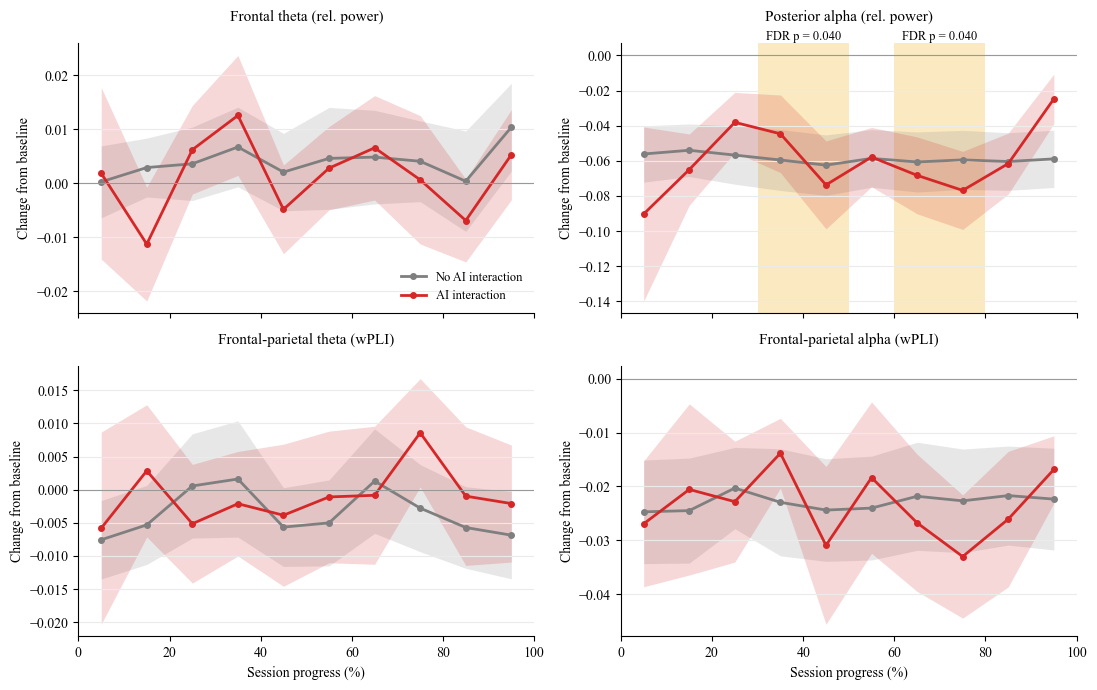

n         p     p_fdr
window step                                   
35-45% Idea generation   4  0.125000  0.125000
       Implementation   10  0.019531  0.029297
65-75% Implementation   11  0.009766  0.029297

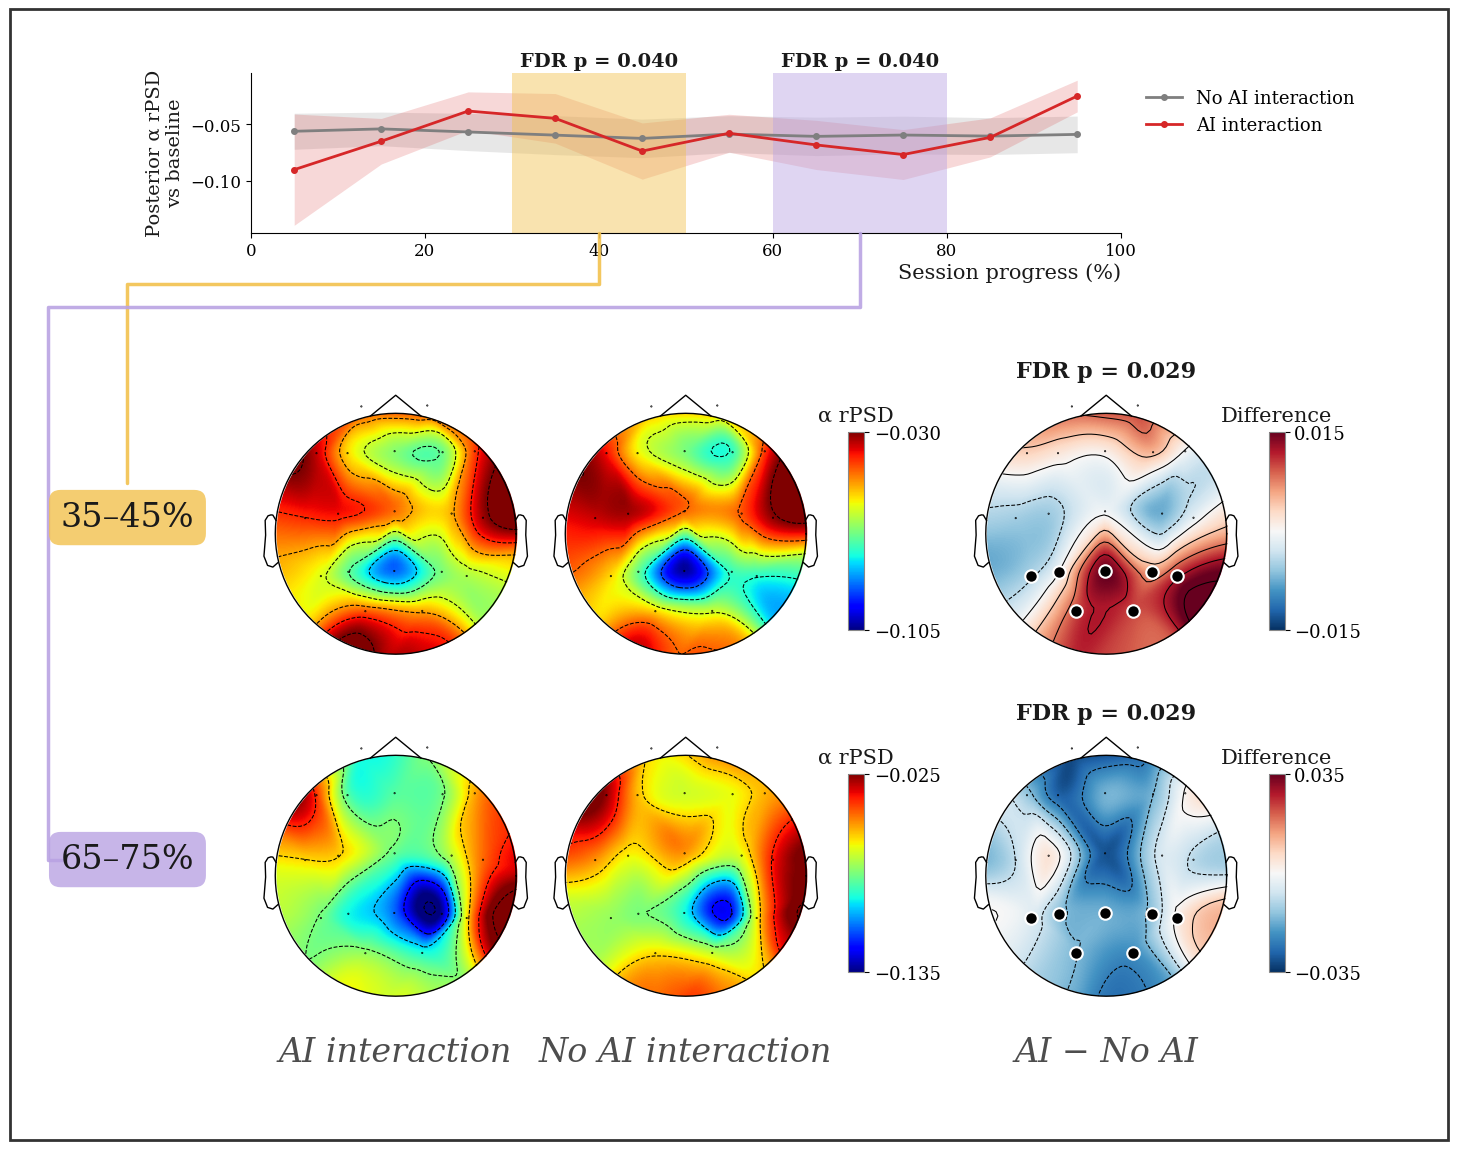

In [36]:
from matplotlib.patches import FancyBboxPatch, Rectangle

TIMES = {'font.family': 'serif', 'font.serif': ['Times New Roman'], 'mathtext.fontset': 'stix'}

# 1. AI interaction and No AI interaction timecourses per feature (vs baseline): participant mean +/- SEM per
#    progress bin; section 13 FDR-significant clusters (tested on the paired AI - No AI difference) shaded
STATE_COLORS = {'No AI interaction': '#7F7F7F', 'AI interaction': '#D62728'}
with plt.rc_context(TIMES):
    bin_half = np.diff(PROGRESS_BINS)[0] * 100 / 2
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
    for ax, feat in zip(axes.ravel(), Q2_DELTA_FEATURES):
        for _, cl in q2_cluster_tests.query('feature == @feat and cluster_p_fdr < 0.05').iterrows():
            ax.axvspan(cl.start_progress_pct - bin_half, cl.end_progress_pct + bin_half, color='#F2C14E', alpha=0.35, lw=0)
            ax.text((cl.start_progress_pct + cl.end_progress_pct) / 2, 1.0, f'FDR p = {cl.cluster_p_fdr:.3f}',
                    transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=9)
        pid_state = unit_time.groupby(['Pid', 'interaction_state', 'progress_bin_pct'])[feat].mean()
        for state, color in STATE_COLORS.items():
            s = pid_state.xs(state, level='interaction_state').groupby('progress_bin_pct').agg(['mean', 'sem'])
            ax.fill_between(s.index, s['mean'] - s['sem'], s['mean'] + s['sem'], color=color, alpha=0.18, lw=0)
            ax.plot(s.index, s['mean'], 'o-', color=color, lw=2, ms=4, label=state)
        ax.axhline(0, color='0.6', lw=0.8)
        ax.set_title(feat.replace(' vs baseline', ''), fontsize=11, pad=16)
        ax.set_ylabel('Change from baseline')
        ax.grid(axis='y', color='0.92')
        ax.spines[['top', 'right']].set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel('Session progress (%)')
        ax.set_xlim(0, 100)
    axes[0, 0].legend(frameon=False, fontsize=9)
    fig.tight_layout()
    display(fig)  # helper modules switch matplotlib to the non-interactive Agg backend, so plt.show() would draw nothing
    plt.close(fig)

# 2. Implementation topomaps per session window: AI interaction, No AI interaction, and AI - No AI.
#    State maps use only session x bin cells that have both states (the data the test uses).
#    Posterior ROI test: Wilcoxon on the ROI mean of the per-participant difference, FDR across step x window
#    cells with >= 3 participants; marked on the difference maps.
POSTERIOR_ROI = ['P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2']
roi = q2_alpha_pid_diff.assign(roi=q2_alpha_pid_diff[POSTERIOR_ROI].mean(axis=1))
roi_tests = roi.groupby(['window', 'step']).roi.agg(
    n='count', p=lambda v: stats.wilcoxon(v).pvalue if len(v) >= 3 else np.nan).dropna()
roi_tests['p_fdr'] = stats.false_discovery_control(roi_tests.p)
display(roi_tests)

STEP = 'Implementation'
paired_cells = q2_alpha_cells.xs(STEP, level='step').dropna()
maps = {}
for window in Q2_TOPO_WINDOWS:
    w = paired_cells.xs(window, level='window')
    for state in ('AI interaction', 'No AI interaction'):
        maps[window, state] = w.xs(state, level='state', axis=1).groupby('Pid').mean()[ALL_CHANNELS].mean().to_numpy()
    maps[window, 'diff'] = q2_alpha_pid_diff.query('window == @window and step == @STEP')[ALL_CHANNELS].mean().to_numpy()
INK, MUTED = '#1A1A1A', '#4D4D4D'
COLUMNS = [('AI interaction', 'AI interaction'), ('No AI interaction', 'No AI interaction'), ('diff', 'AI − No AI')]
round_out = lambda v: np.ceil(v / 0.005) * 0.005
row_scales = {}  # per row: AI / No AI share a range fit to their values; the difference is centred on 0
for window in Q2_TOPO_WINDOWS:
    states = np.concatenate([maps[window, 'AI interaction'], maps[window, 'No AI interaction']])
    d_lim = round_out(np.abs(maps[window, 'diff']).max())
    row_scales[window] = {'state': (-round_out(-states.min()), round_out(states.max()), 'jet'), 'diff': (-d_lim, d_lim, 'RdBu_r')}

topo_info = mne.create_info(ALL_CHANNELS, 300.0, 'eeg').set_montage('standard_1020')
# per row: [AI][No AI][α rPSD bar] [AI - No AI][difference bar]
# above the rows: posterior alpha timecourse strip with the two windows shaded and linked to their rows
MAP_W, BAR_GAP, BAR_W, left, top, cell_h = 0.2, 0.012, 0.011, 0.17, 0.7, 0.3
POST_FEAT = 'Posterior alpha (rel. power) vs baseline'
WINDOW_COLORS = dict(zip(Q2_TOPO_WINDOWS, ['#F2C14E', '#B9A3E3']))
x_pos = {'AI interaction': left, 'No AI interaction': left + MAP_W, 'diff': left + 2 * MAP_W + 0.09}
bar_x = {'state': left + 2 * MAP_W + BAR_GAP, 'diff': x_pos['diff'] + MAP_W + BAR_GAP}
with plt.rc_context(TIMES):
    fig = plt.figure(figsize=(14.5, 11.4))
    tax = fig.add_axes([left, 0.8, 0.6, 0.14])
    pid_state = unit_time.groupby(['Pid', 'interaction_state', 'progress_bin_pct'])[POST_FEAT].mean()
    for state, color in STATE_COLORS.items():
        ts = pid_state.xs(state, level='interaction_state').groupby('progress_bin_pct').agg(['mean', 'sem'])
        tax.fill_between(ts.index, ts['mean'] - ts['sem'], ts['mean'] + ts['sem'], color=color, alpha=0.18, lw=0)
        tax.plot(ts.index, ts['mean'], 'o-', color=color, lw=2, ms=4, label=state)
    for window, (lo, hi) in Q2_TOPO_WINDOWS.items():
        lo_pct, hi_pct = lo * 100, hi * 100
        tax.axvspan(lo_pct, hi_pct, color=WINDOW_COLORS[window], alpha=0.45, lw=0)
        cl = q2_cluster_tests.query('feature == @POST_FEAT and cluster_p_fdr < 0.05 and start_progress_pct >= @lo_pct and end_progress_pct <= @hi_pct')
        if len(cl):
            tax.text((lo_pct + hi_pct) / 2, 1.02, f'FDR p = {cl.cluster_p_fdr.min():.3f}', transform=tax.get_xaxis_transform(),
                     ha='center', va='bottom', fontsize=14, fontweight='bold', color=INK)
    tax.set_xlim(0, 100)
    tax.set_xlabel('Session progress (%)', fontsize=15, color=INK, labelpad=2, loc='right')  # clear of the connectors
    tax.set_ylabel('Posterior α rPSD\nvs baseline', fontsize=14, color=INK)
    tax.tick_params(labelsize=12)
    tax.spines[['top', 'right']].set_visible(False)
    tax.legend(frameon=False, fontsize=13, loc='upper left', bbox_to_anchor=(1.01, 1.0))
    for key, title in COLUMNS:
        # column titles under the bottom row, leaving the band below the strip for the connectors
        fig.text(x_pos[key] + MAP_W / 2, top - len(Q2_TOPO_WINDOWS) * cell_h - 0.005, title, fontsize=24, fontstyle='italic',
                 ha='center', va='top', color=MUTED)
    for r, window in enumerate(Q2_TOPO_WINDOWS):
        y0 = top - (r + 1) * cell_h
        label_xy = (0.085, y0 + cell_h / 2)
        fig.text(*label_xy, window.replace('-', '–'), fontsize=24, ha='center', va='center', color=INK,
                 bbox=dict(boxstyle='round,pad=0.35', facecolor=WINDOW_COLORS[window], edgecolor='none', alpha=0.8))
        # elbow connector from the shaded window down the left margin to the row label (never crosses a map):
        # row r leaves the strip, runs left at its own height, drops in its own lane, then enters the label
        lo, hi = Q2_TOPO_WINDOWS[window]
        x0, y0_fig = fig.transFigure.inverted().transform(tax.transData.transform(((lo + hi) * 50, tax.get_ylim()[0])))
        band_y, lane_x = 0.755 - 0.02 * r, label_xy[0] - 0.055 * r
        path = [(x0, y0_fig), (x0, band_y), (lane_x, band_y)]
        path += [(lane_x, label_xy[1] + 0.03)] if r == 0 else [(lane_x, label_xy[1]), (label_xy[0] - 0.045, label_xy[1])]
        fig.add_artist(plt.Line2D(*zip(*path), transform=fig.transFigure, color=WINDOW_COLORS[window], lw=2.5,
                                  alpha=0.9, solid_joinstyle='round', solid_capstyle='round'))
        sig = (window, STEP) in roi_tests.index and roi_tests.loc[(window, STEP), 'p_fdr'] < 0.05
        for key, _ in COLUMNS:
            lo, hi, cmap = row_scales[window]['diff' if key == 'diff' else 'state']
            ax = fig.add_axes([x_pos[key] + 0.008, y0 + 0.06 * cell_h, MAP_W - 0.016, cell_h * 0.84])
            mark = sig and key == 'diff'
            im, cn = mne.viz.plot_topomap(maps[window, key], topo_info, axes=ax, show=False, cmap=cmap,
                                          vlim=(lo, hi), contours=6, extrapolate='head',
                                          mask=np.isin(ALL_CHANNELS, POSTERIOR_ROI) if mark else None,
                                          mask_params=dict(marker='o', markersize=9, markerfacecolor='black', markeredgecolor='white', markeredgewidth=1.5))
            # MNE fills slightly past the head outline; clip to the outline it drew (its longest line)
            outline = max(ax.lines, key=lambda ln: len(ln.get_xdata())).get_xydata()
            head = plt.Circle(outline.mean(axis=0), np.linalg.norm(outline - outline.mean(axis=0), axis=1).mean(), transform=ax.transData)
            for artist in (im, cn):
                if artist is not None: artist.set_clip_path(head)
            if mark:
                ax.text(0.5, 1.0, f"FDR p = {roi_tests.loc[(window, STEP), 'p_fdr']:.3f}",
                        ha='center', va='bottom', fontsize=16, fontweight='bold', color=INK, transform=ax.transAxes)
        for scale, label in (('state', 'α rPSD'), ('diff', 'Difference')):
            lo, hi, cmap = row_scales[window][scale]
            cax = fig.add_axes([bar_x[scale], y0 + 0.17 * cell_h, BAR_W, cell_h * 0.58])
            cb = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(lo, hi), cmap=cmap), cax=cax, ticks=[lo, hi])
            cb.ax.tick_params(labelsize=13); cb.outline.set_edgecolor('#888888')
            cb.ax.set_title(label, fontsize=15, pad=8, color=INK)
    fig.patches.append(Rectangle((0.004, 0.004), 0.992, 0.992, transform=fig.transFigure, fill=False, edgecolor='#333333', linewidth=2.0))
display(fig)
plt.close(fig)


## 17. Question 2: narrower sub-windows inside each session window (Implementation)

Within each window from section 13, posterior-ROI relative alpha (AI - No AI) during Implementation is re-binned at `SUB_BIN` resolution. As in section 13, differences are taken within session x sub-bin and averaged per participant, then a sign-flip cluster permutation over adjacent sub-bins locates the sub-window carrying the effect. The windows themselves were chosen from these data, so this refines their location rather than giving an independent test.


In [ ]:
SUB_BIN, N_PERM = 0.05, 500
impl = q2_alpha_epochs.query("step == 'Implementation'").assign(roi=lambda d: d[POSTERIOR_ROI].mean(axis=1))
sub_bins, sub_clusters = [], []
for window, (lo, hi) in Q2_TOPO_WINDOWS.items():
    w = impl.query('window == @window').assign(sub=lambda d: (lo + np.floor((d.progress - lo) / SUB_BIN) * SUB_BIN).round(4))
    cells = w.groupby(['Pid', 'session', 'sub', 'state']).roi.mean().unstack('state')
    diff = (cells['AI interaction'] - cells['No AI interaction']).dropna().groupby(['Pid', 'sub']).mean().unstack('sub')
    subs, arr = diff.columns.to_numpy(float), diff.to_numpy(float)
    t_bins = lambda a: np.array([one_sample_t(a[:, j]) for j in range(a.shape[1])])
    t_obs, n_by = t_bins(arr), np.sum(np.isfinite(arr), axis=0)
    threshold = stats.t.ppf(0.975, df=max(int(n_by.max()) - 1, 1))
    rng = np.random.default_rng(42)  # null: sign-flip each participant's whole sub-bin profile
    null = np.array([max([c[2] for c in cluster_stats_from_t(t_bins(arr * rng.choice([-1.0, 1.0], size=arr.shape[0])[:, None]), threshold)], default=0.0)
                     for _ in range(N_PERM)])
    sub_bins += [dict(window=window, sub_bin=f'{s * 100:.0f}-{(s + SUB_BIN) * 100:.0f}%', n=int(n), mean_ai_minus_no_ai=np.nanmean(arr[:, j]), t=t)
                 for j, (s, n, t) in enumerate(zip(subs, n_by, t_obs))]
    sub_clusters += [dict(window=window, sub_window=f'{subs[s] * 100:.0f}-{(subs[e] + SUB_BIN) * 100:.0f}%', min_n=int(n_by[s:e + 1].min()),
                          mean_ai_minus_no_ai=float(np.nanmean(arr[:, s:e + 1])), cluster_p=(1 + np.sum(null >= stat)) / (N_PERM + 1))
                     for s, e, stat in cluster_stats_from_t(t_obs, threshold)]

print(f'Posterior ROI, Implementation, {SUB_BIN * 100:.0f}% sub-bins:')
display(pd.DataFrame(sub_bins).round(4))
print('Sub-window clusters (|t| above threshold in adjacent sub-bins):')
display(pd.DataFrame(sub_clusters).round(4) if sub_clusters else 'No sub-bin reaches the cluster threshold.')


In [ ]:
# 

## 18. Question 2 figure: posterior alpha timecourse with zoom callouts to the topomaps

Top: posterior alpha over session progress (all Wallas steps pooled), AI vs No AI, with the section 13 FDR-significant windows shaded. Each window flares into a callout with the Implementation topomaps (AI | No AI | AI - No AI, section 16 test). Shown inline only; run after sections 13, 15 and 16.

Saved to /Users/athenasaghi/VSProjects/EEG_CreativityStudy/wallas_analysis/figures/q2_alpha_timecourse_topomaps.{png,pdf}


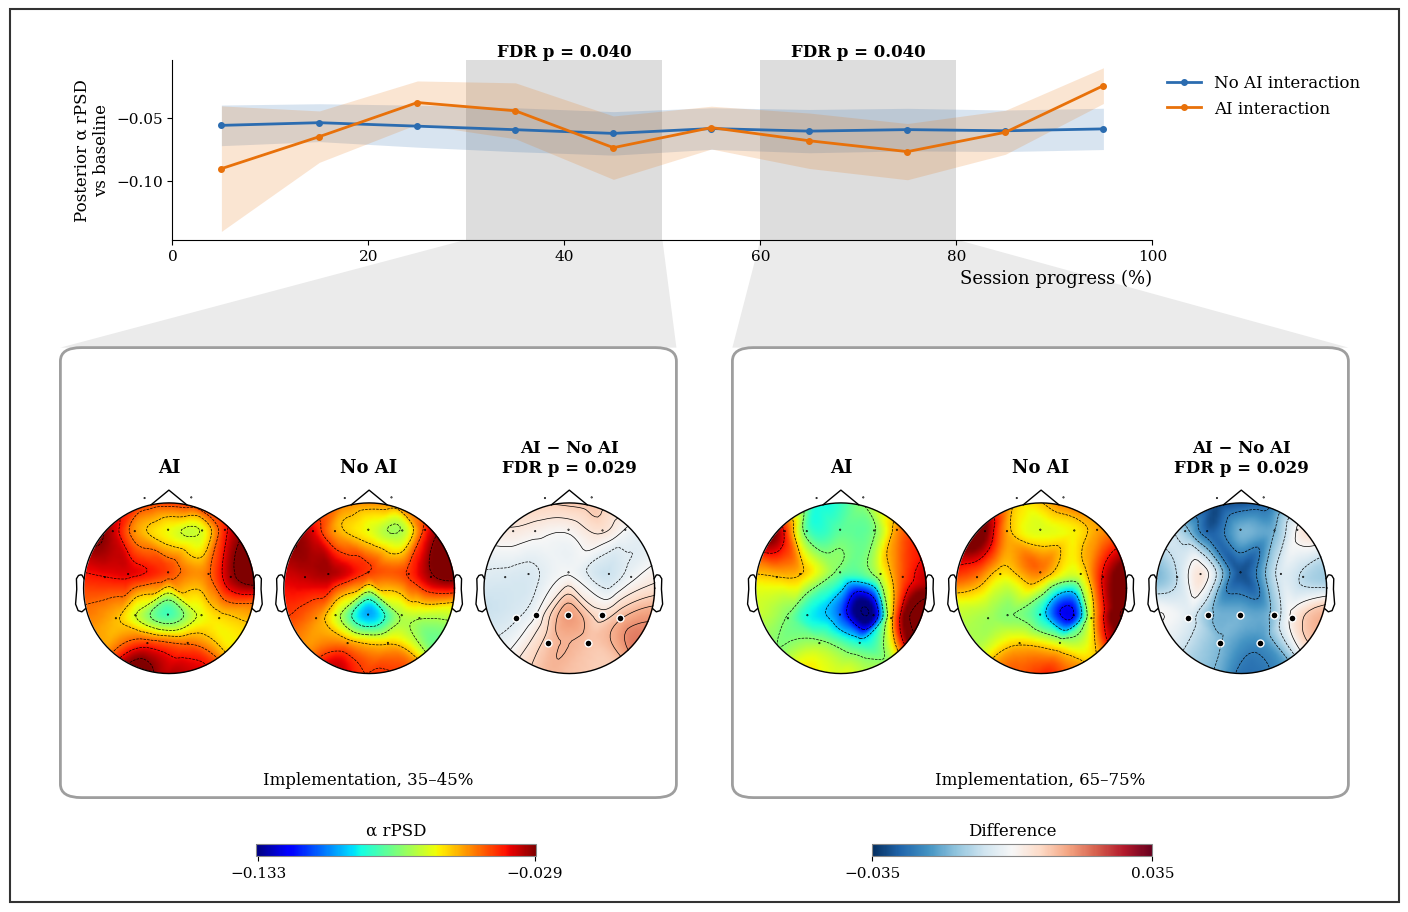

In [45]:
# Posterior alpha over the session (all Wallas steps pooled; section 13 FDR-significant windows shaded) with zoom
# callouts into the Implementation topomaps for each window (AI | No AI | AI - No AI; section 16 test). Shown inline only.
from matplotlib.patches import FancyBboxPatch, Polygon, Rectangle

TIMES = {'font.family': 'serif', 'font.serif': ['Times New Roman'], 'mathtext.fontset': 'stix'}
INK, SIG_GREY = 'black', '#BDBDBD'
STATE_COLORS = {'No AI interaction': '#2B6CB0', 'AI interaction': '#E8710A'}
POST_FEAT = 'Posterior alpha (rel. power) vs baseline'
end_ticks = lambda lo, hi: [np.ceil(lo * 1000) / 1000, np.floor(hi * 1000) / 1000]  # inside the range so they show

pid_state = unit_time.groupby(['Pid', 'interaction_state', 'progress_bin_pct'])[POST_FEAT].mean()
TC_STATE = {st: pid_state.xs(st, level='interaction_state').groupby('progress_bin_pct').agg(['mean', 'sem']) for st in STATE_COLORS}
WIN_P = {}
for window, (lo, hi) in Q2_TOPO_WINDOWS.items():
    cl = q2_cluster_tests.query('feature == @POST_FEAT and cluster_p_fdr < 0.05 and start_progress_pct >= @lo * 100 and end_progress_pct <= @hi * 100')
    WIN_P[window] = cl.cluster_p_fdr.min() if len(cl) else np.nan
ROI_Q = {w: roi_tests.loc[(w, STEP), 'p_fdr'] for w in Q2_TOPO_WINDOWS if (w, STEP) in roi_tests.index}
STATE_LIM = (min(maps[k].min() for k in maps if k[1] != 'diff'), max(maps[k].max() for k in maps if k[1] != 'diff'))
DIFF_LIM = np.ceil(max(np.abs(maps[k]).max() for k in maps if k[1] == 'diff') / 0.005) * 0.005
TOPO_INFO = mne.create_info(ALL_CHANNELS, 300.0, 'eeg').set_montage('standard_1020')


def head(ax, values, vlim, cmap, mark=False):
    """Topomap clipped to the head outline; posterior ROI marked when mark=True."""
    im, cn = mne.viz.plot_topomap(values, TOPO_INFO, axes=ax, show=False, cmap=cmap, vlim=vlim, contours=6, extrapolate='head',
                                  mask=np.isin(ALL_CHANNELS, POSTERIOR_ROI) if mark else None,
                                  mask_params=dict(marker='o', markersize=5, markerfacecolor='black', markeredgecolor='white', markeredgewidth=1))
    outline = max(ax.lines, key=lambda ln: len(ln.get_xdata())).get_xydata()
    clip = plt.Circle(outline.mean(axis=0), np.linalg.norm(outline - outline.mean(axis=0), axis=1).mean(), transform=ax.transData)
    for artist in (im, cn):
        if artist is not None: artist.set_clip_path(clip)


with plt.rc_context(TIMES):
    fig = plt.figure(figsize=(14, 9))
    ax = fig.add_axes([0.12, 0.74, 0.7, 0.2])
    for st, color in STATE_COLORS.items():
        s = TC_STATE[st]
        ax.fill_between(s.index, s['mean'] - s['sem'], s['mean'] + s['sem'], color=color, alpha=0.18, lw=0)
        ax.plot(s.index, s['mean'], 'o-', color=color, lw=2, ms=4, label=st)
    for window, (lo, hi) in Q2_TOPO_WINDOWS.items():
        ax.axvspan(lo * 100, hi * 100, color=SIG_GREY, alpha=0.5, lw=0, zorder=0)
        ax.text((lo + hi) * 50, 1.02, f'FDR p = {WIN_P[window]:.3f}', transform=ax.get_xaxis_transform(), ha='center', fontsize=12, fontweight='bold', color=INK)
    ax.set_xlim(0, 100)
    ax.set_xlabel('Session progress (%)', fontsize=13, loc='right', color=INK)
    ax.set_ylabel('Posterior α rPSD\nvs baseline', fontsize=12, color=INK)
    ax.tick_params(labelsize=11)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, fontsize=12, loc='upper left', bbox_to_anchor=(1.0, 1.0), labelcolor=INK)
    fig.canvas.draw()

    box_w, box_h, box_y = 0.44, 0.5, 0.12
    for b, (window, (lo, hi)) in enumerate(Q2_TOPO_WINDOWS.items()):
        bx = 0.04 + b * (box_w + 0.04)
        # translucent wedge from the shaded window down to its callout box
        (x_lo, y_ax), (x_hi, _) = fig.transFigure.inverted().transform(ax.transData.transform([(lo * 100, ax.get_ylim()[0]), (hi * 100, ax.get_ylim()[0])]))
        fig.patches.append(Polygon([(x_lo, y_ax), (x_hi, y_ax), (bx + box_w, box_y + box_h), (bx, box_y + box_h)], closed=True,
                                   transform=fig.transFigure, facecolor=SIG_GREY, alpha=0.3, edgecolor='none', zorder=-1))
        fig.patches.append(FancyBboxPatch((bx, box_y), box_w, box_h, transform=fig.transFigure, boxstyle='round,pad=0,rounding_size=0.015',
                                          facecolor='white', edgecolor='#9E9E9E', linewidth=2, zorder=-0.5))
        for k, (key, title) in enumerate((('AI interaction', 'AI'), ('No AI interaction', 'No AI'), ('diff', 'AI − No AI'))):
            hax = fig.add_axes([bx + 0.01 + k * 0.143, box_y + 0.06, 0.135, box_h - 0.14])
            if key == 'diff':
                head(hax, maps[window, key], (-DIFF_LIM, DIFF_LIM), 'RdBu_r', mark=True)
                hax.set_title(f'{title}\nFDR p = {ROI_Q[window]:.3f}', fontsize=12, color=INK, fontweight='bold')
            else:
                head(hax, maps[window, key], STATE_LIM, 'jet')
                hax.set_title(title, fontsize=13, color=INK, fontweight='bold')
        fig.text(bx + box_w / 2, box_y + 0.015, f"Implementation, {window.replace('-', '–')}", ha='center', fontsize=12, color=INK)

    for rect, vlim, cmap, label in (([0.18, 0.055, 0.2, 0.014], STATE_LIM, 'jet', 'α rPSD'),
                                    ([0.62, 0.055, 0.2, 0.014], (-DIFF_LIM, DIFF_LIM), 'RdBu_r', 'Difference')):
        cax = fig.add_axes(rect)
        cb = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(*vlim), cmap=cmap), cax=cax, orientation='horizontal', ticks=end_ticks(*vlim))
        cb.ax.tick_params(labelsize=11); cb.outline.set_edgecolor('#888888'); cb.ax.set_title(label, fontsize=12, color=INK)
    fig.patches.append(Rectangle((0.004, 0.004), 0.992, 0.992, transform=fig.transFigure, fill=False, edgecolor='#333333', linewidth=1.5))
FIG_DIR = PROJECT / 'wallas_analysis' / 'figures'
FIG_DIR.mkdir(exist_ok=True)
for ext, kw in (('png', dict(dpi=600)), ('pdf', {})):  # high-resolution raster + vector copy
    fig.savefig(FIG_DIR / f'q2_alpha_timecourse_topomaps.{ext}', bbox_inches='tight', pad_inches=0.05, facecolor='white', **kw)
print('Saved to', FIG_DIR / 'q2_alpha_timecourse_topomaps.{png,pdf}')
display(fig)
plt.close(fig)
